# DeepTrust-X v4.1: final experiments (resumable)

v4.1 fixes USAD (min-max scaling and sigmoid decoders, as in the original paper; the v4 version collapsed to a constant score). To update an existing v4 run, delete only the `USAD` files in the Drive folder and press Run all.

One notebook for every remaining experiment in the paper review:

| Review item | What this notebook does |
|---|---|
| Fixed false-alarm budgets | Thresholds = 95/98/99th percentile of benign validation scores (label-free); TPR at 1/2/5% FPR |
| Hybrid detector | **DeepTrust-X + Isolation Forest** fused with tail p-values (label-free); every baseline is fused the same way |
| More baselines | **One-Class SVM**, **Dense-AE** (non-temporal), **USAD** (Audibert et al., KDD 2020) |
| Unrealistic pure windows | **Mixed-window test** on the time-ordered traffic stream (benign and attack flows interleaved) |
| Explanations vs SHAP | Permutation-SHAP on the same windows: rank agreement and runtime |
| Explanations vs data | KS-separation agreement and the repair (faithfulness) test |
| Ablations, cost | Gate, LSTM branch, dilation, gating, temporal compression; params and latency for all models |

**Two runs are needed** (each resumable; finished runs are skipped after a disconnect):
1. `DROP_FEATURES = ("Dst Port",)`: main, robust setting (default)
2. `DROP_FEATURES = ()`: all features, for comparison with earlier results (you can set `RUN_ABLATIONS = False` here to save time)

In [ ]:
# CELL 1: install and download
!pip -q install awscli scikit-learn pandas numpy matplotlib seaborn scipy
import os
BASE = "/content" if os.path.isdir("/content") else os.getcwd()
os.makedirs(f"{BASE}/data", exist_ok=True)
CSV = f"{BASE}/data/Friday-02-03-2018.csv"
if not os.path.exists(CSV):
    !aws s3 cp --no-sign-request "s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/Friday-02-03-2018_TrafficForML_CICFlowMeter.csv" "{CSV}"
!ls -lh {BASE}/data

total 337M
-rw-r--r-- 1 root root 337M Oct 11  2018 Friday-02-03-2018.csv


In [ ]:
# CELL 2: configuration
import os, glob, json, time, copy, random, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from scipy.stats import ks_2samp, spearmanr
from sklearn.preprocessing import RobustScaler
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

BASE = "/content" if os.path.isdir("/content") else os.getcwd()
SAVE_DIR = f"{BASE}/deeptrust_runs_v4"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/deeptrust_runs_v4"
except Exception:
    pass

CFG = dict(
    DATA_PATH   = f"{BASE}/data/Friday-02-03-2018.csv",   # file or folder of CSVs
    OUT_DIR     = f"{BASE}/deeptrust_v4",
    SAVE_DIR    = SAVE_DIR,
    DROP_FEATURES = (),      # main setting. () = all features
    SORT_BY_TIME = True,                # order flows by Timestamp (needed for the mixed-window test)
    LABEL_COL   = None,
    BENIGN_NAME = "BENIGN",
    WINDOW      = 32,
    TRAIN_STRIDE= 4,
    VAL_STRIDE  = 8,
    TEST_STRIDE = 32,
    BLOCK       = 4096,
    SPLIT       = (0.6, 0.2, 0.2),
    CLIP        = 20.0,
    HIDDEN      = 64,
    EPOCHS      = 60,
    STEPS_PER_EPOCH = 300,
    WARMUP_STEPS = 300,
    PATIENCE    = 8,
    BATCH       = 256,
    LR          = 1e-3,
    WD          = 1e-4,
    NOISE_STD   = 0.10,
    MASK_P      = 0.10,
    TOPK_SCORE  = 5,
    MAIN_SCORE  = "mse",
    BUDGETS     = (0.99, 0.98, 0.95),   # label-free thresholds (quantiles of benign validation scores)
    TEST_FPR    = (0.01, 0.02, 0.05),
    SEEDS       = (0, 1, 2),
    RUN_ABLATIONS = True,
    RUN_BASELINES = True,
    SHAP_WINDOWS = 100,                 # attack windows explained with SHAP
    SHAP_PERMS   = 32,                  # permutations per window per reference
    SHAP_REFS    = 3,                   # benign reference windows per explained window
    EXPLAIN_MODEL = "Ablation: ungated blocks",   # model analysed in the explanation section (see notes)
)
CFG.update(globals().get("CFG_OVERRIDE", {}))
CFG["TAG"] = ("no_" + "_".join(re.sub(r"\W+", "", d).lower() for d in CFG["DROP_FEATURES"])) if CFG["DROP_FEATURES"] else "all_features"
os.makedirs(CFG["OUT_DIR"], exist_ok=True); os.makedirs(CFG["SAVE_DIR"], exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| saving to:", CFG["SAVE_DIR"], "| setting:", CFG["TAG"])
if DEVICE == "cpu": print("WARNING: no GPU. Switch the runtime to a GPU.")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | saving to: /content/drive/MyDrive/deeptrust_runs_v4 | setting: all_features


In [ ]:
# CELL 3: load, order by time, blocked split, transform, pure and mixed test windows
ID_COLS = {"flow id", "flow_id", "src ip", "dst ip", "source ip", "destination ip", "src_ip", "dst_ip",
           "timestamp", "src port", "source port", "src_port", "flowid"}

def read_all(path):
    files = [path] if os.path.isfile(path) else sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
    if not files: raise FileNotFoundError(path)
    frames = []
    for f in files:
        d = pd.read_csv(f, low_memory=False); d.columns = d.columns.astype(str).str.strip()
        frames.append(d); print(f"read {os.path.basename(f)}: {d.shape}")
    return pd.concat(frames, ignore_index=True)

df = read_all(CFG["DATA_PATH"])
label_col = CFG["LABEL_COL"] or next(c for c in df.columns if c.lower() in ("label", "attack", "class", "attack_type"))
df = df[df[label_col].astype(str).str.strip().str.upper() != label_col.upper()]   # repeated header rows
ts_col = next((c for c in df.columns if c.lower() == "timestamp"), None)
if CFG["SORT_BY_TIME"] and ts_col is not None:
    t = pd.to_datetime(df[ts_col], dayfirst=True, errors="coerce")
    df = df.iloc[np.argsort(t.values, kind="stable")]
    print(f"ordered by {ts_col}: {t.min()} -> {t.max()} ({t.isna().sum()} unparsed)")
df = df.reset_index(drop=True)
labels = df[label_col].astype(str).str.strip().str.upper()
print("Label counts:\n", labels.value_counts())

feat = df.drop(columns=[c for c in df.columns if c == label_col or c.lower() in ID_COLS])
feat = feat.apply(pd.to_numeric, errors="coerce").astype("float64")
feat = feat.replace([np.inf, -np.inf], np.nan).fillna(0.0)
is_benign = labels.eq(CFG["BENIGN_NAME"]).to_numpy()
raw = feat.to_numpy()
benign_raw, attack_raw = raw[is_benign], raw[~is_benign]
print(f"benign flows {len(benign_raw):,} | attack flows {len(attack_raw):,}")

def block_split(n, block, fracs, rng):
    nb = math.ceil(n / block); order = rng.permutation(nb)
    a, b = int(nb * fracs[0]), int(nb * (fracs[0] + fracs[1]))
    to_segs = lambda ids: [(i * block, min((i + 1) * block, n)) for i in np.sort(ids)]
    return to_segs(order[:a]), to_segs(order[a:b]), to_segs(order[b:])

split_rng = np.random.default_rng(12345)
seg_tr, seg_va, seg_te = block_split(len(benign_raw), CFG["BLOCK"], CFG["SPLIT"], split_rng)
seg_vaA, seg_vaB = seg_va[0::2], seg_va[1::2]
train_rows = np.concatenate([np.arange(s, e) for s, e in seg_tr])

tr = benign_raw[train_rows]
keep = tr.std(axis=0) > 0
_, uniq_idx = np.unique(tr[:, keep].round(6), axis=1, return_index=True)
keep_idx = np.where(keep)[0][np.sort(uniq_idx)]
_drop = {d.strip().lower() for d in CFG["DROP_FEATURES"]}
keep_idx = np.array([i for i in keep_idx if str(feat.columns[i]).strip().lower() not in _drop])
FEATURES = list(feat.columns[keep_idx]); F = len(FEATURES)
print("dropped by config:", [c for c in feat.columns if c.strip().lower() in _drop], "| features kept:", F)

slog = lambda a: np.sign(a) * np.log1p(np.abs(a))
scaler = RobustScaler().fit(slog(tr[:, keep_idx]))
def transform(a):
    z = scaler.transform(slog(a[:, keep_idx]))
    return np.clip(np.nan_to_num(z), -CFG["CLIP"], CFG["CLIP"]).astype("float32")
stream = transform(raw)                      # every flow, in time order
benign, attack = stream[is_benign], stream[~is_benign]
_trb = benign[train_rows]; USAD_LO, USAD_HI = _trb.min(0).astype("float32"), _trb.max(0).astype("float32")   # USAD only

def window_starts(segs, W, stride):
    st = []
    for s, e in segs: st.extend(range(s, e - W + 1, stride))
    return np.array(st, dtype=np.int64)
def gather(arr, starts, W): return arr[starts[:, None] + np.arange(W)[None, :]]

W = CFG["WINDOW"]
tr_starts = window_starts(seg_tr, W, CFG["TRAIN_STRIDE"])
va_starts = window_starts(seg_va, W, CFG["VAL_STRIDE"])
vaA_w = gather(benign, window_starts(seg_vaA, W, CFG["VAL_STRIDE"]), W)
vaB_w = gather(benign, window_starts(seg_vaB, W, CFG["VAL_STRIDE"]), W)
te_ben_w = gather(benign, window_starts(seg_te, W, CFG["TEST_STRIDE"]), W)
all_att_starts = np.arange(0, len(attack) - W + 1, CFG["TEST_STRIDE"])
pick = np.linspace(0, len(all_att_starts) - 1, min(len(te_ben_w), len(all_att_starts))).astype(int)
te_att_w = gather(attack, all_att_starts[pick], W)
X_test = np.concatenate([te_ben_w, te_att_w])
y_test = np.r_[np.zeros(len(te_ben_w), int), np.ones(len(te_att_w), int)]

# ---- mixed-window test: consecutive flows of the real time-ordered stream ----
# A window is kept only if every benign flow in it belongs to the benign TEST split (no train/val leakage).
# Label = 1 if the window contains at least one attack flow; the attack fraction is kept for analysis.
split_of_benign = np.full(len(benign_raw), -1)
for k, segs in enumerate((seg_tr, seg_va, seg_te)):
    for s, e in segs: split_of_benign[s:e] = k
flow_ok = np.ones(len(stream), bool)
flow_ok[np.where(is_benign)[0]] = split_of_benign == 2
starts_all = np.arange(0, len(stream) - W + 1, W)
ok_c = np.r_[0, np.cumsum(flow_ok)]; att_c = np.r_[0, np.cumsum(~is_benign)]
win_ok = (ok_c[starts_all + W] - ok_c[starts_all]) == W
mix_starts = starts_all[win_ok]
mix_frac = (att_c[mix_starts + W] - att_c[mix_starts]) / W
X_mix = gather(stream, mix_starts, W); y_mix = (mix_frac > 0).astype(int)
print(f"pure test: {len(te_ben_w):,} benign + {len(te_att_w):,} attack windows | mixed test: {len(X_mix):,} windows "
      f"({(mix_frac == 0).sum():,} benign-only, {((mix_frac > 0) & (mix_frac < 1)).sum():,} mixed, {(mix_frac == 1).sum():,} attack-only)")

benign_t = torch.tensor(benign, device=DEVICE)
ar_W = torch.arange(W, device=DEVICE)
def batch_from_starts(starts_np, idx):
    s = torch.as_tensor(starts_np[idx], device=DEVICE)
    return benign_t[s[:, None] + ar_W[None, :]]

read Friday-02-03-2018.csv: (1048575, 80)
ordered by Timestamp: 2018-03-02 01:00:00 -> 2018-03-02 12:59:59 (0 unparsed)
Label counts:
 Label
BENIGN    762384
BOT       286191
Name: count, dtype: int64
benign flows 762,384 | attack flows 286,191
dropped by config: [] | features kept: 61
pure test: 4,752 benign + 4,752 attack windows | mixed test: 6,916 windows (2,015 benign-only, 4,440 mixed, 461 attack-only)


In [ ]:
# CELL 4: models. Every model returns (reconstruction, embedding)
H = CFG["HIDDEN"]

class FeatureGate(nn.Module):
    # squeeze-and-excitation over features: one weight in (0,1) per feature per window,
    # computed from the window's per-feature mean and std
    def __init__(self, f, r=4):
        super().__init__()
        m = max(16, f // r)
        self.mlp = nn.Sequential(nn.Linear(2 * f, m), nn.GELU(), nn.Linear(m, f))
        nn.init.zeros_(self.mlp[-1].weight); nn.init.constant_(self.mlp[-1].bias, 2.0)   # starts ~pass-through
    def forward(self, x):                                   # x: (B, T, F)
        ctx = torch.cat([x.mean(1), x.std(1)], -1)
        return torch.sigmoid(self.mlp(ctx)).unsqueeze(1)    # (B, 1, F)

class DilatedBlock(nn.Module):
    # WaveNet-style block: gated (tanh*sigmoid) or plain ReLU; residual + skip outputs, no normalisation
    def __init__(self, c, dilation, k=3, gated=True):
        super().__init__()
        self.gated = gated
        self.conv = nn.Conv1d(c, 2 * c if gated else c, k, padding=dilation * (k - 1) // 2, dilation=dilation)
        self.res, self.skip = nn.Conv1d(c, c, 1), nn.Conv1d(c, c, 1)
    def forward(self, x):
        h = self.conv(x)
        if self.gated:
            a, b = h.chunk(2, dim=1); h = torch.tanh(a) * torch.sigmoid(b)
        else:
            h = torch.relu(h)
        return x + self.res(h), self.skip(h)

class DeepTrustX3(nn.Module):
    # feature gate -> 1x1 projection -> [ gated dilated conv stack (main) || BiLSTM (side) ] -> 1x1 fuse -> output
    def __init__(self, f, h=H, dilations=(1, 2, 4, 8), use_gate=True, use_lstm=True,
                 gated=True, compress=False):
        super().__init__()
        self.gate = FeatureGate(f) if use_gate else None
        self.inp = nn.Conv1d(f, h, 1)
        self.compress = compress
        if compress:   # only used by the ablation that reproduces the v2 bottleneck finding
            self.down = nn.Sequential(nn.Conv1d(h, h, 3, stride=2, padding=1), nn.GELU(),
                                      nn.Conv1d(h, h, 3, stride=2, padding=1), nn.GELU())
            self.up = nn.Sequential(nn.ConvTranspose1d(h, h, 4, stride=2, padding=1), nn.GELU(),
                                    nn.ConvTranspose1d(h, h, 4, stride=2, padding=1), nn.GELU())
        self.blocks = nn.ModuleList([DilatedBlock(h, d, gated=gated) for d in dilations])
        self.lstm = nn.LSTM(h, h // 2, batch_first=True, bidirectional=True) if use_lstm else None
        self.mix = nn.Conv1d(2 * h if use_lstm else h, h, 1)
        self.out = nn.Conv1d(h, f, 1)

    def gate_values(self, x):
        return self.gate(x) if self.gate is not None else torch.ones_like(x[:, :1, :])

    def forward(self, x):
        z = self.inp((x * self.gate_values(x)).transpose(1, 2))          # (B, h, T)
        c = self.down(z) if self.compress else z
        skip = 0
        for blk in self.blocks:
            c, s = blk(c); skip = skip + s
        c = torch.relu(skip)
        if self.compress: c = self.up(c)
        if self.lstm is not None:
            l, _ = self.lstm(z.transpose(1, 2)); c = torch.cat([c, l.transpose(1, 2)], 1)
        m = torch.relu(self.mix(c))
        return self.out(m).transpose(1, 2), m.mean(2)

class LSTMAE(nn.Module):
    def __init__(self, f, h=H):
        super().__init__(); self.enc = nn.LSTM(f, h, batch_first=True)
        self.dec = nn.LSTM(h, h, batch_first=True); self.out = nn.Linear(h, f)
    def forward(self, x):
        z, _ = self.enc(x); d, _ = self.dec(z); return self.out(d), z.mean(1)

class GRUAE(nn.Module):
    def __init__(self, f, h=H):
        super().__init__(); self.enc = nn.GRU(f, h, batch_first=True)
        self.dec = nn.GRU(h, h, batch_first=True); self.out = nn.Linear(h, f)
    def forward(self, x):
        z, _ = self.enc(x); d, _ = self.dec(z); return self.out(d), z.mean(1)

class TCNBlock(nn.Module):
    def __init__(self, c, d):
        super().__init__()
        self.b = nn.Sequential(nn.Conv1d(c, c, 3, padding=d, dilation=d), nn.ReLU(), nn.Conv1d(c, c, 1))
    def forward(self, x): return torch.relu(x + self.b(x))

class TCNAE(nn.Module):
    def __init__(self, f, h=H):
        super().__init__(); self.inp = nn.Conv1d(f, h, 1)
        self.tcn = nn.Sequential(*[TCNBlock(h, d) for d in (1, 2, 4, 8)]); self.out = nn.Conv1d(h, f, 1)
    def forward(self, x):
        z = self.tcn(self.inp(x.transpose(1, 2))); return self.out(z).transpose(1, 2), z.mean(2)

class TransformerAE(nn.Module):
    def __init__(self, f, h=H):
        super().__init__(); self.inp = nn.Linear(f, h)
        self.pos = nn.Parameter(torch.zeros(1, CFG["WINDOW"], h))
        layer = nn.TransformerEncoderLayer(h, 4, 2 * h, 0.1, batch_first=True)
        self.enc = nn.TransformerEncoder(layer, 2); self.out = nn.Linear(h, f)
    def forward(self, x):
        z = self.enc(self.inp(x) + self.pos); return self.out(z), z.mean(1)

def n_params(m): return sum(p.numel() for p in m.parameters())

# width of the param-matched TCN baseline: smallest h whose size >= DeepTrust-X v3
_target = n_params(DeepTrustX3(F))
H_TCN_MATCHED = next(h for h in range(H, 4 * H, 4) if n_params(TCNAE(F, h)) >= _target)

def model_zoo(f):
    zoo = {"DeepTrust-X v3 (Proposed)": lambda: DeepTrustX3(f)}
    if CFG["RUN_BASELINES"]:
        zoo.update({"LSTM-AE": lambda: LSTMAE(f), "GRU-AE": lambda: GRUAE(f), "TCN-AE": lambda: TCNAE(f),
                    f"TCN-AE (param-matched, h={H_TCN_MATCHED})": lambda: TCNAE(f, H_TCN_MATCHED),
                    "Transformer-AE": lambda: TransformerAE(f)})
    if CFG["RUN_ABLATIONS"]:
        zoo.update({"Ablation: no feature gate":   lambda: DeepTrustX3(f, use_gate=False),
                    "Ablation: no LSTM branch":    lambda: DeepTrustX3(f, use_lstm=False),
                    "Ablation: no dilation (d=1)": lambda: DeepTrustX3(f, dilations=(1, 1, 1, 1)),
                    "Ablation: ungated blocks":    lambda: DeepTrustX3(f, gated=False),
                    "Ablation: + temporal compression (v2)": lambda: DeepTrustX3(f, compress=True)})
    return zoo

for n, mk in model_zoo(F).items():
    print(f"{n:42s} params={n_params(mk()):,}")


class DenseAE(nn.Module):        # non-temporal baseline: the window is flattened
    def __init__(self, f, T=None, latent=128):
        super().__init__(); T = T or CFG["WINDOW"]; n = f * T
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(n, 512), nn.GELU(), nn.Linear(512, latent), nn.Tanh())
        self.dec = nn.Sequential(nn.Linear(latent, 512), nn.GELU(), nn.Linear(512, n)); self.shape = (T, f)
    def forward(self, x):
        z = self.enc(x); return self.dec(z).view(-1, *self.shape), z

class USAD(nn.Module):
    # Audibert et al., KDD 2020, as in the original: inputs min-max scaled with statistics of the benign
    # training flows, sigmoid decoders, one encoder and two decoders trained adversarially.
    def __init__(self, f, T=None, z=64):
        super().__init__(); T = T or CFG["WINDOW"]; n = f * T; self.shape = (T, f)
        self.register_buffer("lo", torch.tensor(USAD_LO)); self.register_buffer("rng", torch.tensor(USAD_HI - USAD_LO + 1e-6))
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(n, n // 2), nn.ReLU(), nn.Linear(n // 2, n // 4), nn.ReLU(),
                                 nn.Linear(n // 4, z), nn.ReLU())
        mk = lambda: nn.Sequential(nn.Linear(z, n // 4), nn.ReLU(), nn.Linear(n // 4, n // 2), nn.ReLU(),
                                   nn.Linear(n // 2, n), nn.Sigmoid())
        self.d1, self.d2 = mk(), mk()
    def scale(self, x): return (x - self.lo) / self.rng          # min-max space (test values may leave [0,1])
    def parts(self, x):
        x = self.scale(x)
        z = self.enc(x); w1 = self.d1(z).view(-1, *self.shape); w2 = self.d2(z).view(-1, *self.shape)
        w3 = self.d2(self.enc(w1)).view(-1, *self.shape); return x, w1, w2, w3
    def forward(self, x):          # used only for timing
        _, w1, _, w3 = self.parts(x); return 0.5 * (w1 + w3), None

DEEP = {"DeepTrust-X v3 (Proposed)": lambda f: DeepTrustX3(f),
        "LSTM-AE": lambda f: LSTMAE(f), "GRU-AE": lambda f: GRUAE(f), "TCN-AE": lambda f: TCNAE(f),
        "TCN-AE (param-matched)": lambda f: TCNAE(f, H_TCN_MATCHED),
        "Transformer-AE": lambda f: TransformerAE(f), "Dense-AE": lambda f: DenseAE(f)}
ABL = {"Ablation: no feature gate": lambda f: DeepTrustX3(f, use_gate=False),
       "Ablation: no LSTM branch": lambda f: DeepTrustX3(f, use_lstm=False),
       "Ablation: no dilation (d=1)": lambda f: DeepTrustX3(f, dilations=(1, 1, 1, 1)),
       "Ablation: ungated blocks": lambda f: DeepTrustX3(f, gated=False),
       "Ablation: + temporal compression": lambda f: DeepTrustX3(f, compress=True)}
ALL_DEEP = {**DEEP, **(ABL if CFG["RUN_ABLATIONS"] else {})}
RUN_NAMES = list(ALL_DEEP) + ["USAD", "Isolation Forest", "One-Class SVM"]
for n in ALL_DEEP: print(f"{n:36s} params={n_params(ALL_DEEP[n](F)):,}")
print(f"{'USAD':36s} params={n_params(USAD(F)):,}")

DeepTrust-X v3 (Proposed)                  params=176,378
LSTM-AE                                    params=69,757
GRU-AE                                     params=53,309
TCN-AE                                     params=73,981
TCN-AE (param-matched, h=104)              params=186,741
Transformer-AE                             params=76,925
Ablation: no feature gate                  params=173,373
Ablation: no LSTM branch                   params=147,194
Ablation: no dilation (d=1)                params=176,378
Ablation: ungated blocks                   params=126,970
Ablation: + temporal compression (v2)      params=233,978
DeepTrust-X v3 (Proposed)            params=176,378
LSTM-AE                              params=69,757
GRU-AE                               params=53,309
TCN-AE                               params=73,981
TCN-AE (param-matched)               params=186,741
Transformer-AE                       params=76,925
Dense-AE                             params=2,133,024
Abla

In [ ]:
# CELL 5: training and scoring
def corrupt(x, noise_std, mask_p):
    if noise_std > 0: x = x + noise_std * torch.randn_like(x)
    if mask_p > 0:    x = x * (torch.rand(x.shape[0], 1, x.shape[2], device=x.device) > mask_p).float()
    return x

@torch.no_grad()
def eval_loss(model, starts):
    model.eval(); tot, n = 0.0, 0
    for i in range(0, len(starts), 1024):
        xb = batch_from_starts(starts, np.arange(i, min(i + 1024, len(starts))))
        rec, _ = model(xb); tot += ((rec - xb) ** 2).mean().item() * len(xb); n += len(xb)
    return tot / n

def train(model, seed):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WD"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    rng = np.random.default_rng(seed)
    best, best_state, bad, hist, step = float("inf"), copy.deepcopy(model.state_dict()), 0, [], 0
    for ep in range(CFG["EPOCHS"]):
        model.train(); losses = []
        for _ in range(CFG["STEPS_PER_EPOCH"]):
            if step < CFG["WARMUP_STEPS"]:
                for g in opt.param_groups: g["lr"] = CFG["LR"] * (step + 1) / CFG["WARMUP_STEPS"]
            xb = batch_from_starts(tr_starts, rng.integers(0, len(tr_starts), CFG["BATCH"]))
            rec, _ = model(corrupt(xb, CFG["NOISE_STD"], CFG["MASK_P"]))
            loss = ((rec - xb) ** 2).mean()          # target = clean input
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            losses.append(loss.item()); step += 1
        vl = eval_loss(model, va_starts)
        if not np.isfinite(vl): print("   non-finite val loss, stopping"); break
        sched.step(vl); hist.append((np.mean(losses), vl))
        if vl < best - 1e-6: best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        if bad >= CFG["PATIENCE"]: break
    model.load_state_dict(best_state)
    print(f"   epochs run {ep + 1}, best benign-val MSE {best:.5f}")
    return model, hist

@torch.no_grad()
def infer(model, X, bs=1024):
    # R: per-window, per-feature mean squared residual (N,F).  mean(R, axis=1) == window MSE exactly.
    model.eval(); R, E = [], []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], device=DEVICE)
        rec, emb = model(xb)
        R.append(((rec - xb) ** 2).mean(1).cpu().numpy()); E.append(emb.cpu().numpy())
    return np.vstack(R), np.vstack(E)

def rank_2s(ref_sorted, s):
    # two-sided empirical p-value against benign reference, returned as -log(p): label-free and
    # robust to skewed score distributions (fixes the median/MAD version used in v2)
    n = len(ref_sorted)
    lo = np.searchsorted(ref_sorted, s, side="right")
    hi = n - np.searchsorted(ref_sorted, s, side="left")
    p = np.minimum(1.0, 2.0 * (np.minimum(lo, hi) + 1) / (n + 1))
    return -np.log(p)

class Scorer:
    # every statistic is fitted on benign val-A only
    def fit(self, R, E):
        self.med = np.median(R, 0); self.mad = 1.4826 * np.median(np.abs(R - self.med), 0) + 1e-6
        self.mu = E.mean(0); self.prec = LedoitWolf().fit(E).precision_
        mse, rec, lat = self._raw(R, E)
        self.ref = {k: np.sort(v) for k, v in (("mse", mse), ("recon", rec), ("latent", lat))}
        self.z = {k: (np.median(v), np.median(np.abs(v - np.median(v))) + 1e-12) for k, v in self.ref.items()}
        return self
    def norm_resid(self, R): return (R - self.med) / self.mad
    def _raw(self, R, E):
        rec = np.sort(self.norm_resid(R), 1)[:, -CFG["TOPK_SCORE"]:].mean(1)
        D = E - self.mu
        lat = np.sqrt(np.einsum("ij,jk,ik->i", D, self.prec, D).clip(0))
        return R.mean(1), rec, lat
    def score(self, R, E):
        mse, rec, lat = self._raw(R, E)
        zs = lambda k, v: (v - self.z[k][0]) / self.z[k][1]
        r = {k: rank_2s(self.ref[k], v) for k, v in (("mse", mse), ("recon", rec), ("latent", lat))}
        return {"mse": mse,                                              # MAIN score (same for all AEs)
                "fused_1s": zs("recon", rec) + zs("latent", lat),        # v2 fused score, one-sided
                "mse_rank2s": r["mse"], "latent_rank2s": r["latent"],
                "fused_rank2s": np.maximum.reduce([r["mse"], r["recon"], r["latent"]])}

SC_KINDS = ("mse", "fused_1s", "mse_rank2s", "latent_rank2s", "fused_rank2s")


def train_usad(model, seed):
    # USAD two-phase objective, same step budget and optimiser as the other models
    model = model.to(DEVICE); rng = np.random.default_rng(seed)
    p1 = list(model.enc.parameters()) + list(model.d1.parameters())
    p2 = list(model.enc.parameters()) + list(model.d2.parameters())
    o1 = torch.optim.AdamW(p1, lr=CFG["LR"], weight_decay=CFG["WD"]); o2 = torch.optim.AdamW(p2, lr=CFG["LR"], weight_decay=CFG["WD"])
    mse = lambda a, b: ((a - b) ** 2).mean(); hist = []
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); ls = []
        for _ in range(CFG["STEPS_PER_EPOCH"]):
            xb = batch_from_starts(tr_starts, rng.integers(0, len(tr_starts), CFG["BATCH"]))
            x01, w1, w2, w3 = model.parts(xb)
            l1 = mse(x01, w1) / ep + (1 - 1 / ep) * mse(x01, w3)
            o1.zero_grad(); l1.backward(); nn.utils.clip_grad_norm_(p1, 1.0); o1.step()
            x01, w1, w2, w3 = model.parts(xb)
            l2 = mse(x01, w2) / ep - (1 - 1 / ep) * mse(x01, w3)
            o2.zero_grad(); l2.backward(); nn.utils.clip_grad_norm_(p2, 1.0); o2.step()
            ls.append(l1.item())
        hist.append((np.mean(ls), np.nan))
    return model, hist

@torch.no_grad()
def usad_score(model, X, bs=1024, alpha=0.5):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], device=DEVICE); x01, w1, _, w3 = model.parts(xb)
        out.append((alpha * ((x01 - w1) ** 2).mean((1, 2)) + (1 - alpha) * ((x01 - w3) ** 2).mean((1, 2))).cpu().numpy())
    return np.concatenate(out)

def window_stats(X): return np.concatenate([X.mean(1), X.std(1), X.max(1), X.min(1)], 1)

In [ ]:
# CELL 6: resumable training of every model x seed
SAVE, TAG = CFG["SAVE_DIR"], CFG["TAG"]
def safe(n): return re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_")
def run_path(name, seed): return f"{SAVE}/{TAG}__{safe(name)}__s{seed}"

ref = f"{SAVE}/{TAG}__labels.npz"
if os.path.exists(ref):
    r = np.load(ref)
    assert np.array_equal(r["y_test"], y_test) and np.array_equal(r["y_mix"], y_mix), "test sets differ from the saved run"
else:
    np.savez_compressed(ref, y_test=y_test, y_mix=y_mix, mix_frac=mix_frac)

todo = [(s, n) for s in CFG["SEEDS"] for n in RUN_NAMES if not os.path.exists(run_path(n, s) + ".npz")]
print(f"{len(todo)} runs left")
for seed, name in todo:
    t0 = time.time(); print(f"\n[seed {seed}] {name}"); seed_everything(seed)
    sub = tr_starts[np.random.default_rng(seed).choice(len(tr_starts), min(20000, len(tr_starts)), replace=False)]
    extra = {}
    if name == "Isolation Forest":
        m = IsolationForest(n_estimators=300, random_state=seed, n_jobs=-1).fit(window_stats(gather(benign, sub, W)))
        sc = lambda X: -m.score_samples(window_stats(X))
    elif name == "One-Class SVM":
        m = OneClassSVM(kernel="rbf", nu=0.01, gamma="scale").fit(window_stats(gather(benign, sub[:10000], W)))
        sc = lambda X: -m.decision_function(window_stats(X))
    elif name == "USAD":
        model, hist = train_usad(USAD(F), seed); sc = lambda X: usad_score(model, X)
        torch.save(model.state_dict(), run_path(name, seed) + ".pt"); extra = dict(params=n_params(model))
    else:
        model, hist = train(ALL_DEEP[name](F), seed); sc = lambda X: infer(model, X)[0].mean(1)
        torch.save(model.state_dict(), run_path(name, seed) + ".pt")
        extra = dict(params=n_params(model), epochs=len(hist), hist=np.array(hist))
    sB, sT, sM = sc(vaB_w), sc(X_test), sc(X_mix)
    np.savez_compressed(run_path(name, seed) + ".npz", valB=sB, test=sT, mix=sM, **extra)
    p = sT > np.quantile(sB[1::2], 0.99)
    print("   pure-test AUC %.4f | acc@1%% %.4f | mixed-test AUC %.4f | %.0fs" % (
        roc_auc_score(y_test, sT), accuracy_score(y_test, p), roc_auc_score(y_mix, sM), time.time() - t0))
print("\nall runs finished")

45 runs left

[seed 0] DeepTrust-X v3 (Proposed)
   epochs run 60, best benign-val MSE 0.00182
   pure-test AUC 0.9954 | acc@1% 0.8217 | mixed-test AUC 0.9743 | 259s

[seed 0] LSTM-AE
   epochs run 60, best benign-val MSE 0.00355
   pure-test AUC 0.9867 | acc@1% 0.5101 | mixed-test AUC 0.8779 | 78s

[seed 0] GRU-AE
   epochs run 60, best benign-val MSE 0.00386
   pure-test AUC 0.9889 | acc@1% 0.5002 | mixed-test AUC 0.9040 | 71s

[seed 0] TCN-AE
   epochs run 60, best benign-val MSE 0.00196
   pure-test AUC 0.9971 | acc@1% 0.9969 | mixed-test AUC 0.9673 | 90s

[seed 0] TCN-AE (param-matched)
   epochs run 60, best benign-val MSE 0.00126
   pure-test AUC 0.9976 | acc@1% 0.9964 | mixed-test AUC 0.9744 | 200s

[seed 0] Transformer-AE
   epochs run 60, best benign-val MSE 0.00167
   pure-test AUC 0.9968 | acc@1% 0.9972 | mixed-test AUC 0.8943 | 149s

[seed 0] Dense-AE
   epochs run 60, best benign-val MSE 0.08769
   pure-test AUC 0.0294 | acc@1% 0.4977 | mixed-test AUC 0.3542 | 57s

[seed 

In [ ]:
# CELL 7: results tables (alone and fused with Isolation Forest)
# Protocol (label-free): benign val-B is split into two interleaved halves. Half N is the benign reference
# for tail p-values (fusion); half C calibrates every threshold. Labels are used only for evaluation.
def tail(refv, s):
    r = np.sort(refv); n = len(r); ge = n - np.searchsorted(r, s, side="left")
    return -np.log((ge + 1) / (n + 1))
def at(y, sC, sT, q):
    thr = np.quantile(sC, q); p = sT > thr
    tp = int((p & (y == 1)).sum()); fp = int((p & (y == 0)).sum()); tn = int((~p & (y == 0)).sum()); fn = int((~p & (y == 1)).sum())
    return dict(Accuracy=(tp + tn) / len(y), Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1),
                F1=2 * tp / max(2 * tp + fp + fn, 1), FPR=fp / max(fp + tn, 1))
def tpr_at(y, s, f): fpr, tpr, _ = roc_curve(y, s); return float(np.interp(f, fpr, tpr))

def load_run(name, seed):
    f = run_path(name, seed) + ".npz"
    return np.load(f) if os.path.exists(f) else None

def variants(name, seed):
    d = load_run(name, seed); I = load_run("Isolation Forest", seed)
    if d is None: return {}
    v = {"alone": {k: d[k] for k in ("valB", "test", "mix")}}
    if I is not None and name not in ("Isolation Forest",):
        N, NI = d["valB"][0::2], I["valB"][0::2]
        v["+ IF (fused)"] = {k: tail(N, d[k]) + tail(NI, I[k]) for k in ("valB", "test", "mix")}
    return v

rows = []
for name in RUN_NAMES:
    for seed in CFG["SEEDS"]:
        for var, s in variants(name, seed).items():
            C = s["valB"][1::2]
            base = dict(Model=name, Variant=var, Seed=seed,
                        AUC=roc_auc_score(y_test, s["test"]), PR_AUC=average_precision_score(y_test, s["test"]),
                        MIX_AUC=roc_auc_score(y_mix, s["mix"]), MIX_PR_AUC=average_precision_score(y_mix, s["mix"]),
                        **{f"TPR@{int(f*100)}%": tpr_at(y_test, s["test"], f) for f in CFG["TEST_FPR"]})
            for q in CFG["BUDGETS"]:
                rows.append({**base, "q": q, **at(y_test, C, s["test"], q),
                             **{f"MIX_{k}": v for k, v in at(y_mix, C, s["mix"], q).items()}})
res = pd.DataFrame(rows); res.to_csv(f"{CFG['OUT_DIR']}/{TAG}_per_seed.csv", index=False)

pm = lambda g, c: f"{100 * g[c].mean():.2f} ± {100 * g[c].std(ddof=0):.2f}"
pm4 = lambda g, c: f"{g[c].mean():.4f} ± {g[c].std(ddof=0):.4f}"
def table(df, cols, fmt=pm):
    return pd.DataFrame([{"Model": m, "Variant": v, "seeds": len(g), **{c: fmt(g, c) for c in cols}}
                         for (m, v), g in df.groupby(["Model", "Variant"], sort=False)])
main = res[~res.Model.str.startswith("Ablation")]
out = {}
for q in CFG["BUDGETS"]:
    print(f"\n=== Table 1 ({TAG}): pure test windows, threshold = {q} quantile of benign val (≈{(1-q)*100:.0f}% false-alarm budget) ===")
    out[f"T1_q{q}"] = table(main[main.q == q], ["Accuracy", "Precision", "Recall", "F1", "FPR"]); display(out[f"T1_q{q}"])
print(f"\n=== Table 2 ({TAG}): threshold-free metrics, pure test windows ===")
out["T2"] = table(main[main.q == CFG["BUDGETS"][0]], ["AUC", "PR_AUC"], pm4).merge(
    table(main[main.q == CFG["BUDGETS"][0]], [c for c in res.columns if c.startswith("TPR@")]), on=["Model", "Variant", "seeds"])
display(out["T2"])
for q in CFG["BUDGETS"][:2]:
    print(f"\n=== Table 3 ({TAG}): MIXED windows from the real traffic stream, q={q} ===")
    out[f"T3_q{q}"] = table(main[main.q == q], ["MIX_Precision", "MIX_Recall", "MIX_F1", "MIX_FPR"]).merge(
        table(main[main.q == q], ["MIX_AUC", "MIX_PR_AUC"], pm4), on=["Model", "Variant", "seeds"]); display(out[f"T3_q{q}"])
abl = res[res.Model.str.startswith("Ablation") | res.Model.str.contains("Proposed")]
if len(abl.Model.unique()) > 1:
    for q in CFG["BUDGETS"][:2]:
        print(f"\n=== Table 4 ({TAG}): ablations, q={q} ===")
        out[f"T4_q{q}"] = table(abl[abl.q == q], ["Accuracy", "Recall", "FPR", "F1"]).merge(
            table(abl[abl.q == q], ["AUC"], pm4), on=["Model", "Variant", "seeds"]); display(out[f"T4_q{q}"])
for k, t in out.items(): t.to_csv(f"{CFG['OUT_DIR']}/{TAG}_{k}.csv", index=False)

# recall on mixed windows by attack fraction (seed 0), q = 0.99
lab = np.load(ref); mf = lab["mix_frac"]
bins = [(0, 0), (1e-9, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 0.999), (1, 1)]
rec = []
for name in ["DeepTrust-X v3 (Proposed)", "Ablation: ungated blocks", "Isolation Forest", "TCN-AE (param-matched)", "USAD"]:
    for var, s in variants(name, CFG["SEEDS"][0]).items():
        thr = np.quantile(s["valB"][1::2], CFG["BUDGETS"][0]); p = s["mix"] > thr
        row = {"Model": name, "Variant": var}
        for lo, hi in bins:
            m = (mf >= lo) & (mf <= hi); key = "benign-only (FPR)" if hi == 0 else ("attack-only" if lo == 1 else f"{lo:.2f}-{hi:.2f}")
            row[f"{key} [n={m.sum()}]"] = round(100 * p[m].mean(), 2) if m.any() else np.nan
        rec.append(row)
rec = pd.DataFrame(rec); print(f"\n=== Table 5 ({TAG}): % of mixed windows flagged, by attack fraction (seed 0, q=0.99) ===")
display(rec); rec.to_csv(f"{CFG['OUT_DIR']}/{TAG}_T5_mixed_by_fraction.csv", index=False)


=== Table 1 (all_features): pure test windows, threshold = 0.99 quantile of benign val (≈1% false-alarm budget) ===


,Model,Variant,seeds,Accuracy,Precision,Recall,F1,FPR
0,DeepTrust-X v3 (Proposed),alone,3,93.91 ± 8.31,99.48 ± 0.13,88.26 ± 16.60,92.66 ± 10.07,0.44 ± 0.03
1,DeepTrust-X v3 (Proposed),+ IF (fused),3,99.77 ± 0.01,99.55 ± 0.02,100.00 ± 0.00,99.77 ± 0.01,0.46 ± 0.02
2,LSTM-AE,alone,3,52.61 ± 2.29,85.78 ± 6.22,5.86 ± 4.64,10.65 ± 7.99,0.63 ± 0.06
3,LSTM-AE,+ IF (fused),3,99.74 ± 0.00,99.49 ± 0.01,100.00 ± 0.00,99.74 ± 0.00,0.51 ± 0.01
4,GRU-AE,alone,3,66.07 ± 21.31,79.22 ± 20.09,32.78 ± 42.61,35.41 ± 43.00,0.65 ± 0.07
5,GRU-AE,+ IF (fused),3,99.71 ± 0.06,99.42 ± 0.13,100.00 ± 0.00,99.71 ± 0.06,0.58 ± 0.13
6,TCN-AE,alone,3,99.67 ± 0.03,99.34 ± 0.05,100.00 ± 0.00,99.67 ± 0.03,0.67 ± 0.05
7,TCN-AE,+ IF (fused),3,99.72 ± 0.02,99.45 ± 0.04,100.00 ± 0.00,99.72 ± 0.02,0.55 ± 0.04
8,TCN-AE (param-matched),alone,3,99.66 ± 0.01,99.32 ± 0.03,100.00 ± 0.00,99.66 ± 0.01,0.68 ± 0.03
9,TCN-AE (param-matched),+ IF (fused),3,99.73 ± 0.02,99.46 ± 0.04,100.00 ± 0.00,99.73 ± 0.02,0.55 ± 0.05



=== Table 1 (all_features): pure test windows, threshold = 0.98 quantile of benign val (≈2% false-alarm budget) ===


,Model,Variant,seeds,Accuracy,Precision,Recall,F1,FPR
0,DeepTrust-X v3 (Proposed),alone,3,99.42 ± 0.06,98.86 ± 0.11,100.00 ± 0.00,99.42 ± 0.06,1.16 ± 0.11
1,DeepTrust-X v3 (Proposed),+ IF (fused),3,99.46 ± 0.04,98.92 ± 0.08,100.00 ± 0.00,99.46 ± 0.04,1.09 ± 0.09
2,LSTM-AE,alone,3,84.82 ± 20.38,96.12 ± 3.41,71.06 ± 40.88,73.88 ± 35.87,1.42 ± 0.13
3,LSTM-AE,+ IF (fused),3,99.37 ± 0.03,98.76 ± 0.07,100.00 ± 0.00,99.38 ± 0.03,1.26 ± 0.07
4,GRU-AE,alone,3,91.26 ± 10.72,98.26 ± 0.56,83.87 ± 21.42,88.94 ± 13.99,1.36 ± 0.09
5,GRU-AE,+ IF (fused),3,99.40 ± 0.06,98.81 ± 0.11,100.00 ± 0.00,99.40 ± 0.06,1.20 ± 0.11
6,TCN-AE,alone,3,99.37 ± 0.03,98.76 ± 0.07,100.00 ± 0.00,99.38 ± 0.03,1.26 ± 0.07
7,TCN-AE,+ IF (fused),3,99.39 ± 0.02,98.80 ± 0.04,100.00 ± 0.00,99.40 ± 0.02,1.21 ± 0.04
8,TCN-AE (param-matched),alone,3,99.42 ± 0.06,98.85 ± 0.12,100.00 ± 0.00,99.42 ± 0.06,1.16 ± 0.12
9,TCN-AE (param-matched),+ IF (fused),3,99.45 ± 0.07,98.90 ± 0.14,100.00 ± 0.00,99.45 ± 0.07,1.11 ± 0.14



=== Table 1 (all_features): pure test windows, threshold = 0.95 quantile of benign val (≈5% false-alarm budget) ===


,Model,Variant,seeds,Accuracy,Precision,Recall,F1,FPR
0,DeepTrust-X v3 (Proposed),alone,3,98.30 ± 0.07,96.71 ± 0.14,100.00 ± 0.00,98.33 ± 0.07,3.40 ± 0.15
1,DeepTrust-X v3 (Proposed),+ IF (fused),3,98.34 ± 0.04,96.78 ± 0.07,100.00 ± 0.00,98.36 ± 0.04,3.32 ± 0.08
2,LSTM-AE,alone,3,98.12 ± 0.09,96.37 ± 0.17,100.00 ± 0.00,98.15 ± 0.09,3.77 ± 0.18
3,LSTM-AE,+ IF (fused),3,98.19 ± 0.04,96.51 ± 0.07,100.00 ± 0.00,98.22 ± 0.04,3.62 ± 0.07
4,GRU-AE,alone,3,98.19 ± 0.05,96.51 ± 0.09,100.00 ± 0.00,98.22 ± 0.05,3.62 ± 0.10
5,GRU-AE,+ IF (fused),3,98.13 ± 0.10,96.40 ± 0.18,100.00 ± 0.00,98.17 ± 0.10,3.74 ± 0.20
6,TCN-AE,alone,3,98.39 ± 0.03,96.87 ± 0.06,100.00 ± 0.00,98.41 ± 0.03,3.23 ± 0.07
7,TCN-AE,+ IF (fused),3,98.24 ± 0.06,96.59 ± 0.10,100.00 ± 0.00,98.27 ± 0.05,3.53 ± 0.11
8,TCN-AE (param-matched),alone,3,98.49 ± 0.13,97.07 ± 0.24,100.00 ± 0.00,98.51 ± 0.13,3.02 ± 0.26
9,TCN-AE (param-matched),+ IF (fused),3,98.34 ± 0.04,96.80 ± 0.07,100.00 ± 0.00,98.37 ± 0.03,3.31 ± 0.07


... (8 outputs left out)


=== Table 4 (all_features): ablations, q=0.98 ===


,Model,Variant,seeds,Accuracy,Recall,FPR,F1,AUC
0,DeepTrust-X v3 (Proposed),alone,3,99.42 ± 0.06,100.00 ± 0.00,1.16 ± 0.11,99.42 ± 0.06,0.9962 ± 0.0008
1,DeepTrust-X v3 (Proposed),+ IF (fused),3,99.46 ± 0.04,100.00 ± 0.00,1.09 ± 0.09,99.46 ± 0.04,0.9992 ± 0.0004
2,Ablation: no feature gate,alone,3,99.36 ± 0.06,100.00 ± 0.00,1.28 ± 0.12,99.37 ± 0.06,0.9958 ± 0.0012
3,Ablation: no feature gate,+ IF (fused),3,99.37 ± 0.06,100.00 ± 0.00,1.27 ± 0.11,99.37 ± 0.05,0.9992 ± 0.0003
4,Ablation: no LSTM branch,alone,3,99.50 ± 0.05,100.00 ± 0.00,1.00 ± 0.10,99.50 ± 0.05,0.9961 ± 0.0010
5,Ablation: no LSTM branch,+ IF (fused),3,99.48 ± 0.04,100.00 ± 0.00,1.05 ± 0.08,99.48 ± 0.04,0.9992 ± 0.0002
6,Ablation: no dilation (d=1),alone,3,99.40 ± 0.06,100.00 ± 0.00,1.20 ± 0.11,99.40 ± 0.06,0.9972 ± 0.0001
7,Ablation: no dilation (d=1),+ IF (fused),3,99.42 ± 0.04,100.00 ± 0.00,1.15 ± 0.08,99.43 ± 0.04,0.9995 ± 0.0001
8,Ablation: ungated blocks,alone,3,99.38 ± 0.04,100.00 ± 0.00,1.25 ± 0.09,99.38 ± 0.04,0.9975 ± 0.0005
9,Ablation: ungated blocks,+ IF (fused),3,99.43 ± 0.06,100.00 ± 0.00,1.14 ± 0.11,99.44 ± 0.06,0.9994 ± 0.0002



=== Table 5 (all_features): % of mixed windows flagged, by attack fraction (seed 0, q=0.99) ===


,Model,Variant,benign-only (FPR) [n=2015],0.00-0.25 [n=1364],0.25-0.50 [n=2455],0.50-0.75 [n=882],0.75-1.00 [n=373],attack-only [n=461]
0,DeepTrust-X v3 (Proposed),alone,0.45,0.29,0.41,0.00,3.75,64.86
1,DeepTrust-X v3 (Proposed),+ IF (fused),0.79,0.59,1.87,17.23,88.20,100.00
2,Ablation: ungated blocks,alone,0.94,3.08,56.29,100.00,100.00,100.00
3,Ablation: ungated blocks,+ IF (fused),0.94,1.17,5.95,32.88,98.39,100.00
4,Isolation Forest,alone,2.18,0.00,0.00,0.00,0.00,0.00
5,TCN-AE (param-matched),alone,0.94,1.47,25.05,99.09,100.00,100.00
6,TCN-AE (param-matched),+ IF (fused),0.99,1.25,5.91,33.33,97.86,100.00
7,USAD,alone,0.94,0.44,0.00,0.00,0.00,0.00
8,USAD,+ IF (fused),0.89,0.37,0.00,0.00,0.00,0.00


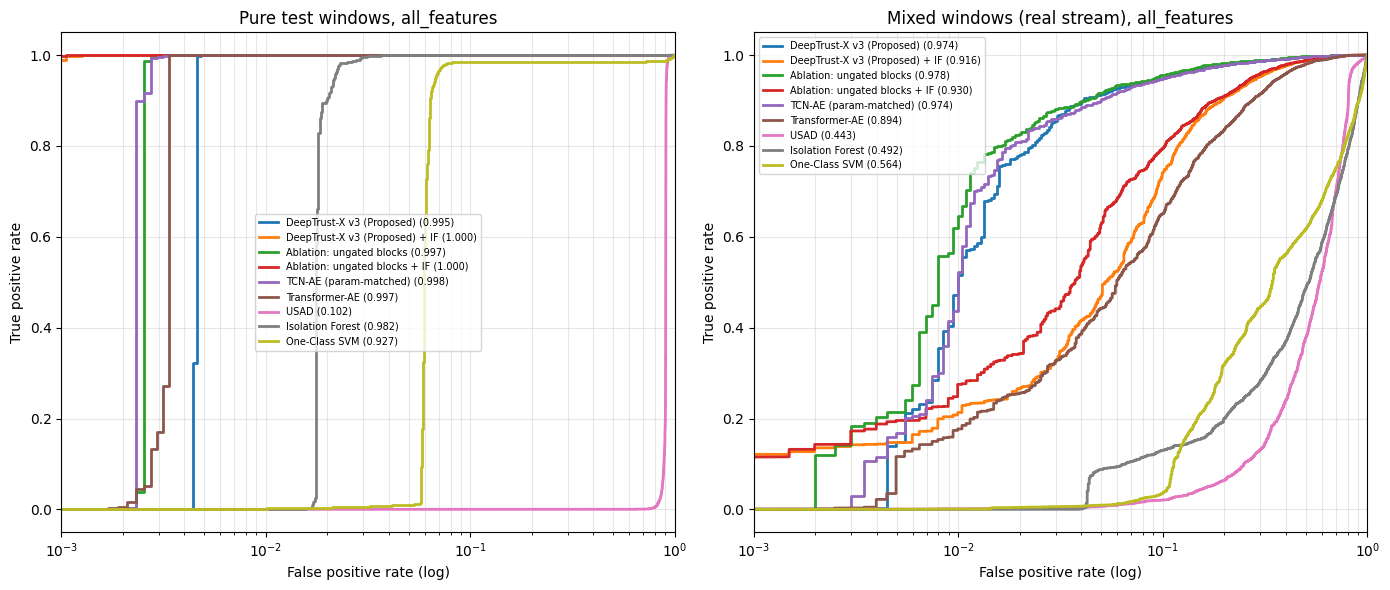

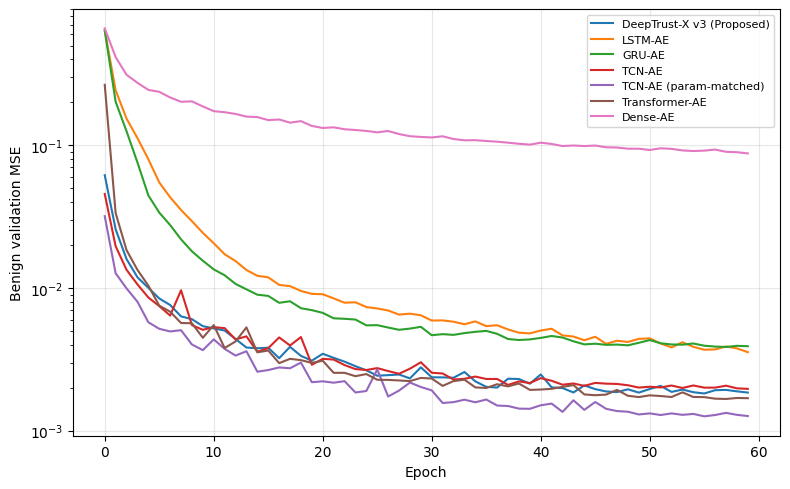

In [ ]:
# CELL 8: figures (seed 0)
OUT = CFG["OUT_DIR"]; s0 = CFG["SEEDS"][0]
show = ["DeepTrust-X v3 (Proposed)", "Ablation: ungated blocks", "TCN-AE (param-matched)", "Transformer-AE", "USAD", "Isolation Forest", "One-Class SVM"]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for name in show:
    for var, s in variants(name, s0).items():
        if var != "alone" and not (name.startswith("DeepTrust") or "ungated" in name): continue
        lbl = name if var == "alone" else f"{name} + IF"
        fpr, tpr, _ = roc_curve(y_test, s["test"]); ax[0].plot(fpr, tpr, lw=2, label=f"{lbl} ({roc_auc_score(y_test, s['test']):.3f})")
        fpr, tpr, _ = roc_curve(y_mix, s["mix"]); ax[1].plot(fpr, tpr, lw=2, label=f"{lbl} ({roc_auc_score(y_mix, s['mix']):.3f})")
for a, t in zip(ax, ("Pure test windows", "Mixed windows (real stream)")):
    a.set_xscale("log"); a.set_xlim(1e-3, 1); a.set_title(f"{t}, {TAG}"); a.set_xlabel("False positive rate (log)")
    a.set_ylabel("True positive rate"); a.grid(alpha=.3, which="both"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/{TAG}_roc.png", dpi=300); plt.show()

plt.figure(figsize=(8, 5))
for name in [n for n in ALL_DEEP if not n.startswith("Ablation")]:
    d = load_run(name, s0)
    if d is not None and "hist" in d.files: plt.plot(d["hist"][:, 1], label=name)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Benign validation MSE"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/{TAG}_loss_curves.png", dpi=300); plt.show()

explaining: Ablation: ungated blocks
flagged attack windows (alone, q=0.99): 4752 / 4752; explaining 4752
{
  "setting": "all_features",
  "explained_windows": 4752,
  "spearman_vs_KS": 0.719090428344791,
  "spearman_vs_KS_p": 6.691071984948488e-11,
  "shap_windows": 100,
  "spearman_vs_SHAP_per_window_mean": -0.28938543110226644,
  "top5_overlap_vs_SHAP_mean": 0.026000000000000002,
  "spearman_vs_SHAP_global": 0.20338445267054464,
  "seconds_per_window_ours": 4.4028759002685544e-05,
  "seconds_per_window_SHAP": 0.07127818584442139,
  "speedup": 1618.900633562571
}
Repair test:


,k,score_drop_top,score_drop_random,alerts_cleared_top,alerts_cleared_random
0,1,0.3751,0.0054,0.0,0.0
1,3,0.3297,0.0153,0.0,0.0
2,5,0.3536,0.0248,0.0,0.0
3,10,0.4968,0.0567,0.0,0.0


,feature,score_share,shap_mean_abs,ks_separation
0,Dst Port,0.4956,0.0055,0.8462
19,Flow IAT Max,0.0415,0.0491,0.5818
34,Fwd Pkts/s,0.0379,0.0171,0.6095
16,Flow Pkts/s,0.0374,0.0156,0.6126
17,Flow IAT Mean,0.0363,0.0425,0.6071
20,Flow IAT Min,0.0356,0.0031,0.2352
28,Bwd IAT Std,0.0327,0.0016,0.3610
35,Bwd Pkts/s,0.0321,0.0131,0.2607
25,Fwd IAT Min,0.0266,0.0024,0.4592
2,Flow Duration,0.0170,0.0463,0.5871


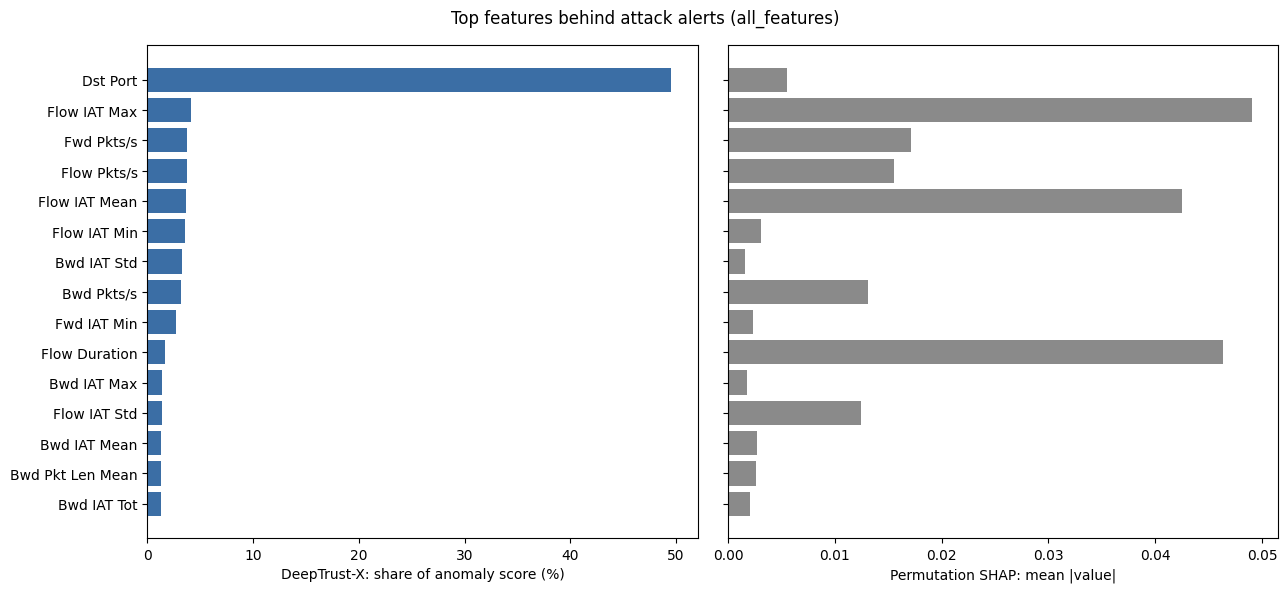

In [ ]:
# CELL 9: explanations: score decomposition, repair test, KS agreement, and comparison with SHAP
name = CFG["EXPLAIN_MODEL"]; s0 = CFG["SEEDS"][0]; print("explaining:", name)
model = ALL_DEEP[name](F).to(DEVICE); model.load_state_dict(torch.load(run_path(name, s0) + ".pt", map_location=DEVICE)); model.eval()
def mse_of(X): return infer(model, X)[0].mean(1)
sB = mse_of(vaB_w); thr = np.quantile(sB[1::2], CFG["BUDGETS"][0])
RT, _ = infer(model, X_test); sT = RT.mean(1)
att = np.where(y_test == 1)[0]; flagged = att[sT[att] > thr]
use = flagged if len(flagged) >= 20 else att[np.argsort(-sT[att])[:max(20, len(flagged))]]
print(f"flagged attack windows (alone, q={CFG['BUDGETS'][0]}): {len(flagged)} / {len(att)}; explaining {len(use)}")
Xa, Ra = X_test[use], RT[use]
share = Ra / Ra.sum(1, keepdims=True); imp = share.mean(0)

# (1) agreement with per-feature KS separation between attack and benign flows
rs = np.random.default_rng(0)
ben_flows, att_flows = X_test[y_test == 0].reshape(-1, F), Xa.reshape(-1, F)
ks = np.array([ks_2samp(ben_flows[rs.choice(len(ben_flows), min(20000, len(ben_flows)), replace=False), j],
                        att_flows[rs.choice(len(att_flows), min(20000, len(att_flows)), replace=False), j]).statistic for j in range(F)])
rho_ks, p_ks = spearmanr(imp, ks)

# (2) repair test: replace top-k explained features with the model's reconstruction
@torch.no_grad()
def recon_of(X): return np.vstack([model(torch.tensor(X[i:i + 1024], device=DEVICE))[0].cpu().numpy() for i in range(0, len(X), 1024)])
Xhat, base = recon_of(Xa), mse_of(Xa); order = np.argsort(-share, 1); rep = []
for k in (1, 3, 5, 10):
    Xt, Xr = Xa.copy(), Xa.copy()
    for i in range(len(Xa)):
        ft, fr = order[i, :k], rs.choice(F, k, replace=False)
        Xt[i][:, ft] = Xhat[i][:, ft]; Xr[i][:, fr] = Xhat[i][:, fr]
    st, sr = mse_of(Xt), mse_of(Xr)
    rep.append(dict(k=k, score_drop_top=np.mean(1 - st / base), score_drop_random=np.mean(1 - sr / base),
                    alerts_cleared_top=np.mean((base > thr) & (st <= thr)), alerts_cleared_random=np.mean((base > thr) & (sr <= thr))))
rep = pd.DataFrame(rep)

# (3) permutation-SHAP on the same score, features masked across the whole window, benign references
def shap_window(x, refw, n_perm, rng):
    T_, F_ = x.shape; perms = [rng.permutation(F_) for _ in range(n_perm)]
    batch = np.empty((n_perm * (F_ + 1), T_, F_), np.float32)
    for p, perm in enumerate(perms):
        cur = refw.copy(); batch[p * (F_ + 1)] = cur
        for k, j in enumerate(perm):
            cur[:, j] = x[:, j]; batch[p * (F_ + 1) + k + 1] = cur
    s = mse_of(batch).reshape(n_perm, F_ + 1); d = np.diff(s, axis=1); phi = np.zeros(F_)
    for p, perm in enumerate(perms): phi[perm] += d[p]
    return phi / n_perm
nS = min(CFG["SHAP_WINDOWS"], len(use)); pick_s = rs.choice(len(use), nS, replace=False)
t0 = time.time(); shap_vals = []
for i in pick_s:
    refs = vaA_w[rs.integers(0, len(vaA_w), CFG["SHAP_REFS"])]
    shap_vals.append(np.mean([shap_window(Xa[i], r, CFG["SHAP_PERMS"], rs) for r in refs], 0))
shap_vals = np.array(shap_vals); t_shap = (time.time() - t0) / nS
t0 = time.time(); _ = infer(model, Xa[pick_s]); t_ours = (time.time() - t0) / nS
rho_w = [spearmanr(share[i], shap_vals[j]).statistic for j, i in enumerate(pick_s)]
top5 = [len(set(np.argsort(-share[i])[:5]) & set(np.argsort(-shap_vals[j])[:5])) / 5 for j, i in enumerate(pick_s)]
rho_glob, _ = spearmanr(imp, np.abs(shap_vals).mean(0))

summary = {"setting": TAG, "explained_windows": int(len(use)),
           "spearman_vs_KS": float(rho_ks), "spearman_vs_KS_p": float(p_ks),
           "shap_windows": int(nS), "spearman_vs_SHAP_per_window_mean": float(np.nanmean(rho_w)),
           "top5_overlap_vs_SHAP_mean": float(np.mean(top5)), "spearman_vs_SHAP_global": float(rho_glob),
           "seconds_per_window_ours": t_ours, "seconds_per_window_SHAP": t_shap, "speedup": t_shap / max(t_ours, 1e-9)}
print(json.dumps(summary, indent=2)); print("Repair test:"); display(rep.round(4))
json.dump(summary, open(f"{CFG['OUT_DIR']}/{TAG}_explanation_summary.json", "w"), indent=2)
rep.to_csv(f"{CFG['OUT_DIR']}/{TAG}_repair_test.csv", index=False)
expl = pd.DataFrame({"feature": FEATURES, "score_share": imp, "shap_mean_abs": np.abs(shap_vals).mean(0), "ks_separation": ks})\
        .sort_values("score_share", ascending=False)
expl.to_csv(f"{CFG['OUT_DIR']}/{TAG}_explanation_features.csv", index=False); display(expl.head(15).round(4))
top = expl.head(15)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
ax[0].barh(top.feature, 100 * top.score_share, color="#3b6ea5"); ax[0].set_xlabel("DeepTrust-X: share of anomaly score (%)")
ax[1].barh(top.feature, top.shap_mean_abs, color="#8a8a8a"); ax[1].set_xlabel("Permutation SHAP: mean |value|")
plt.suptitle(f"Top features behind attack alerts ({TAG})"); plt.tight_layout()
plt.savefig(f"{CFG['OUT_DIR']}/{TAG}_explanation_vs_shap.png", dpi=300); plt.show()

In [ ]:
# CELL 10: cost (seed-0 models) and export
@torch.no_grad()
def bench(m, bs, reps=50):
    m.eval(); xb = torch.tensor(X_test[:bs], device=DEVICE)
    for _ in range(5): m(xb)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(reps): m(xb)
    if DEVICE == "cuda": torch.cuda.synchronize()
    el = (time.perf_counter() - t) / reps; return el * 1000, bs / el
cost = []
for name in list(ALL_DEEP) + ["USAD"]:
    p = run_path(name, CFG["SEEDS"][0]) + ".pt"
    if not os.path.exists(p): continue
    m = (USAD(F) if name == "USAD" else ALL_DEEP[name](F)).to(DEVICE)
    m.load_state_dict(torch.load(p, map_location=DEVICE), strict=False)
    l1, _ = bench(m, 1); _, th = bench(m, 256)
    cost.append({"Model": name, "Params": n_params(m), "Latency ms (batch 1)": round(l1, 3), "Windows/s (batch 256)": round(th),
                 "GPU": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"})
cost = pd.DataFrame(cost); display(cost); cost.to_csv(f"{CFG['OUT_DIR']}/{TAG}_cost.csv", index=False)

import sys, sklearn, shutil
json.dump({**{k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, "features": FEATURES,
           "python": sys.version.split()[0], "torch": torch.__version__, "sklearn": sklearn.__version__},
          open(f"{CFG['OUT_DIR']}/{TAG}_config.json", "w"), indent=2)
zp = shutil.make_archive(f"{CFG['OUT_DIR']}_{TAG}", "zip", CFG["OUT_DIR"]); print("saved", zp)
try:
    from google.colab import files; files.download(zp)
except Exception:
    pass

,Model,Params,Latency ms (batch 1),Windows/s (batch 256),GPU
0,DeepTrust-X v3 (Proposed),176378,1.733,94556,Tesla T4
1,LSTM-AE,69757,0.437,311687,Tesla T4
2,GRU-AE,53309,0.409,340421,Tesla T4
3,TCN-AE,73981,0.710,249633,Tesla T4
4,TCN-AE (param-matched),186741,0.703,94664,Tesla T4
5,Transformer-AE,76925,0.714,148231,Tesla T4
6,Dense-AE,2133024,0.177,957240,Tesla T4
7,Ablation: no feature gate,173373,1.676,96143,Tesla T4
8,Ablation: no LSTM branch,147194,1.413,113456,Tesla T4
9,Ablation: no dilation (d=1),176378,1.874,102156,Tesla T4


saved /content/deeptrust_v4_all_features.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


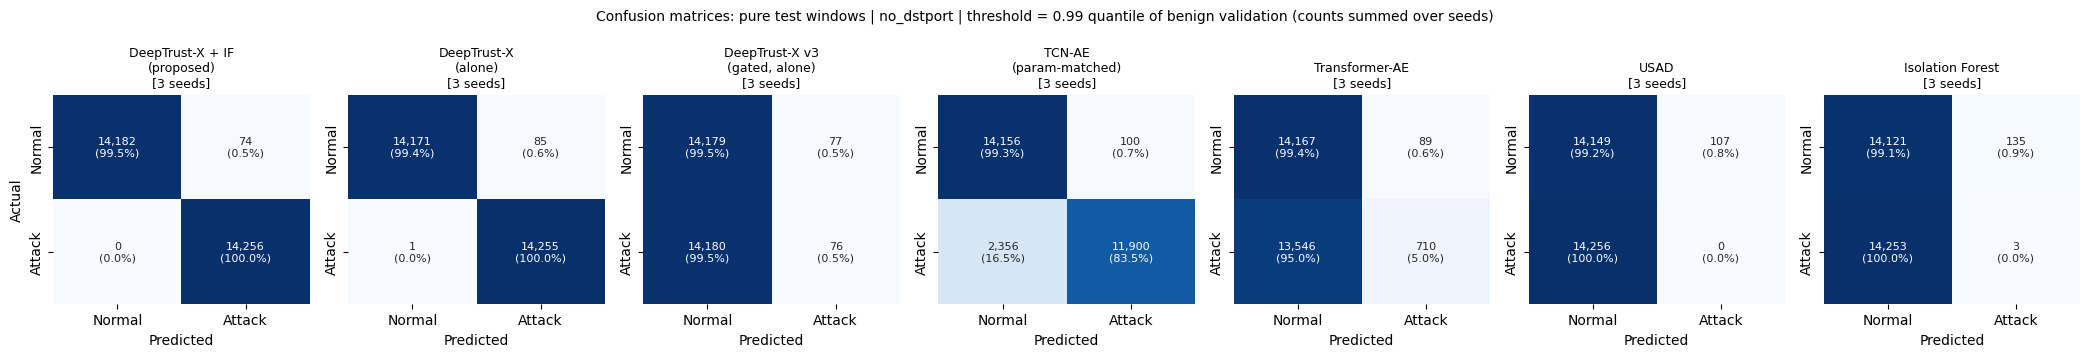

saved /content/confusion_matrices/cm_no_dstport_test_q0.99.png


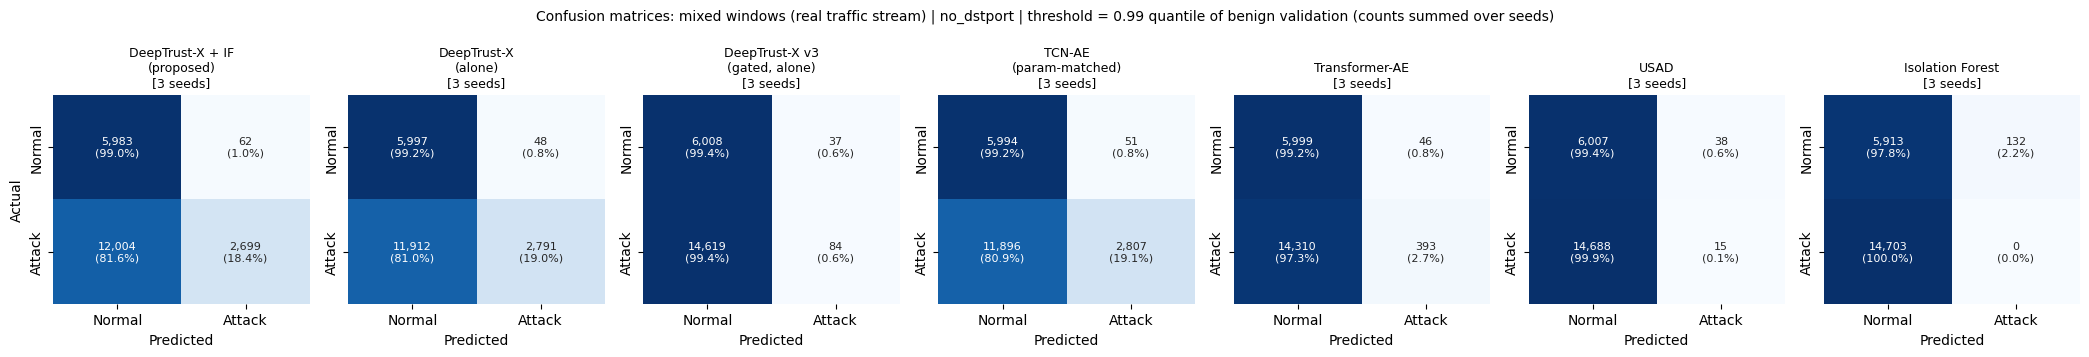

saved /content/confusion_matrices/cm_no_dstport_mix_q0.99.png


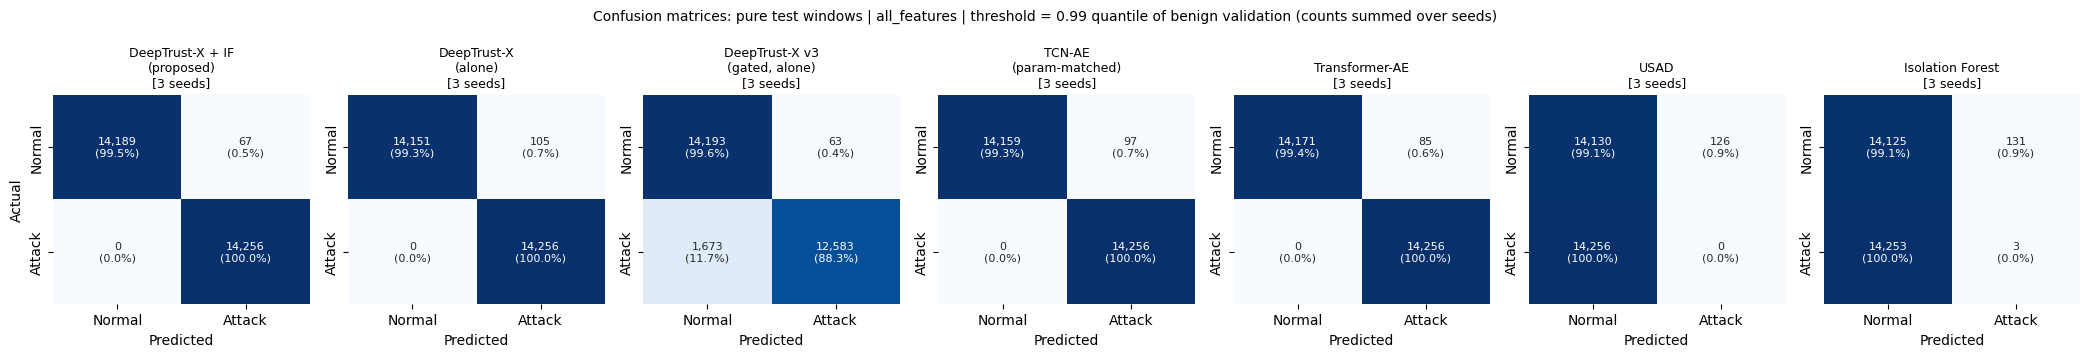

saved /content/confusion_matrices/cm_all_features_test_q0.99.png


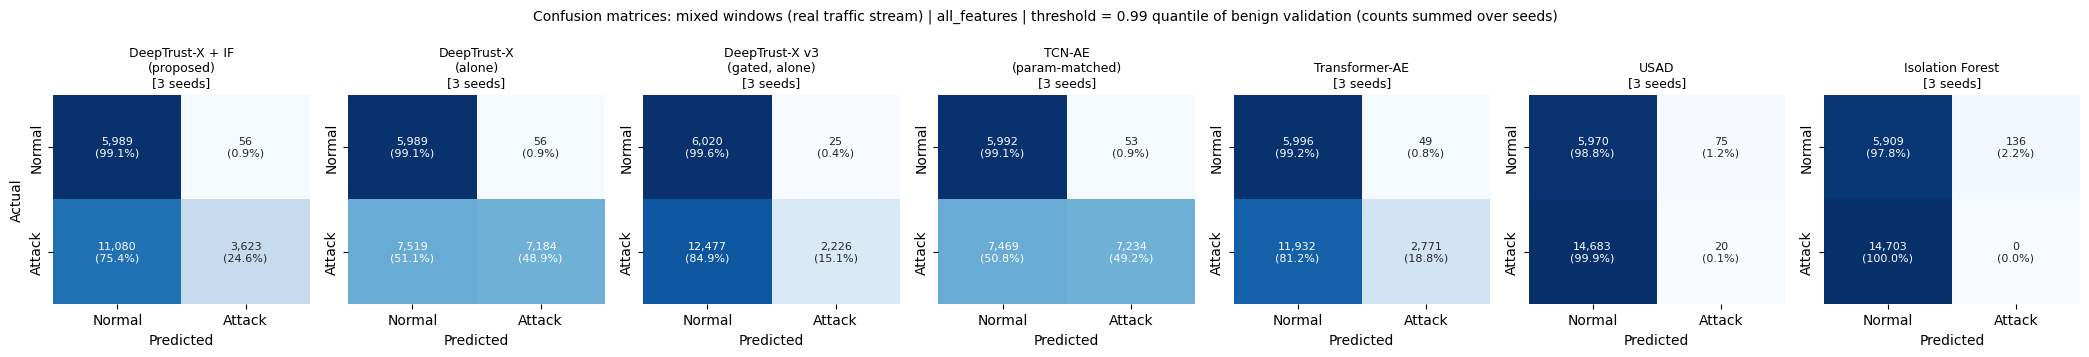

saved /content/confusion_matrices/cm_all_features_mix_q0.99.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CONFUSION MATRICES: same label-free thresholds as Tables 1 and 3. Uses the saved runs, so no training needed.
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from google.colab import drive, files
drive.mount("/content/drive")
SAVE = "/content/drive/MyDrive/deeptrust_runs_v4"
OUT = "/content/confusion_matrices"; os.makedirs(OUT, exist_ok=True)

Q = 0.99                 # 0.99 = 1% benign false-alarm budget (main result); also try 0.98
SEEDS = (0, 1, 2)        # summed over 3 seeds; use (0,) for a single seed
SETTINGS = ("no_dstport", "all_features")
MODELS = [  # (saved run name, variant, label shown in the figure)
    ("Ablation: ungated blocks", "+ IF (fused)", "DeepTrust-X + IF\n(proposed)"),
    ("Ablation: ungated blocks", "alone", "DeepTrust-X\n(alone)"),
    ("DeepTrust-X v3 (Proposed)", "alone", "DeepTrust-X v3\n(gated, alone)"),
    ("TCN-AE (param-matched)", "alone", "TCN-AE\n(param-matched)"),
    ("Transformer-AE", "alone", "Transformer-AE"),
    ("USAD", "alone", "USAD"),
    ("Isolation Forest", "alone", "Isolation Forest"),
]

safe = lambda n: re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_")
def load(tag, name, seed):
    f = f"{SAVE}/{tag}__{safe(name)}__s{seed}.npz"
    return np.load(f) if os.path.exists(f) else None
def tail(refv, s):
    r = np.sort(refv); n = len(r); ge = n - np.searchsorted(r, s, side="left")
    return -np.log((ge + 1) / (n + 1))
def scores(tag, name, var, seed):
    d = load(tag, name, seed)
    if d is None: return None
    if var == "alone": return {k: d[k] for k in ("valB", "test", "mix")}
    I = load(tag, "Isolation Forest", seed)
    if I is None: return None
    N, NI = d["valB"][0::2], I["valB"][0::2]          # same fusion protocol as the tables
    return {k: tail(N, d[k]) + tail(NI, I[k]) for k in ("valB", "test", "mix")}
def confusion(y, pred):
    return np.array([[((y == 0) & ~pred).sum(), ((y == 0) & pred).sum()],
                     [((y == 1) & ~pred).sum(), ((y == 1) & pred).sum()]])

rows = []
for tag in SETTINGS:
    lf = f"{SAVE}/{tag}__labels.npz"
    if not os.path.exists(lf): print("skipping", tag, "(no saved runs)"); continue
    lab = np.load(lf)
    for test_name, y, key in (("pure test windows", lab["y_test"], "test"),
                              ("mixed windows (real traffic stream)", lab["y_mix"], "mix")):
        fig, axes = plt.subplots(1, len(MODELS), figsize=(3.0 * len(MODELS), 3.6))
        for i, (ax, (name, var, label)) in enumerate(zip(axes, MODELS)):
            tot, used = np.zeros((2, 2), int), 0
            for seed in SEEDS:
                s = scores(tag, name, var, seed)
                if s is None: continue
                thr = np.quantile(s["valB"][1::2], Q)      # threshold from benign validation only
                M = confusion(y, s[key] > thr); tot += M; used += 1
                rows.append(dict(setting=tag, test=test_name, model=label.replace("\n", " "), seed=seed,
                                 TN=M[0, 0], FP=M[0, 1], FN=M[1, 0], TP=M[1, 1]))
            pct = 100 * tot / tot.sum(1, keepdims=True).clip(min=1)   # row %: normal row = TNR/FPR, attack row = miss/recall
            annot = np.array([[f"{tot[r, c]:,}\n({pct[r, c]:.1f}%)" for c in range(2)] for r in range(2)])
            sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                        xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], annot_kws={"fontsize": 8})
            ax.set_title(f"{label}\n[{used} seed{'s' if used != 1 else ''}]", fontsize=9)
            ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if i == 0 else "")
        fig.suptitle(f"Confusion matrices: {test_name} | {tag} | threshold = {Q} quantile of benign validation "
                     f"(counts summed over seeds)", fontsize=10)
        plt.tight_layout()
        fn = f"{OUT}/cm_{tag}_{key}_q{Q}.png"; plt.savefig(fn, dpi=300, bbox_inches="tight"); plt.show(); print("saved", fn)

pd.DataFrame(rows).to_csv(f"{OUT}/confusion_matrices_q{Q}.csv", index=False)
import shutil; files.download(shutil.make_archive(OUT, "zip", OUT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


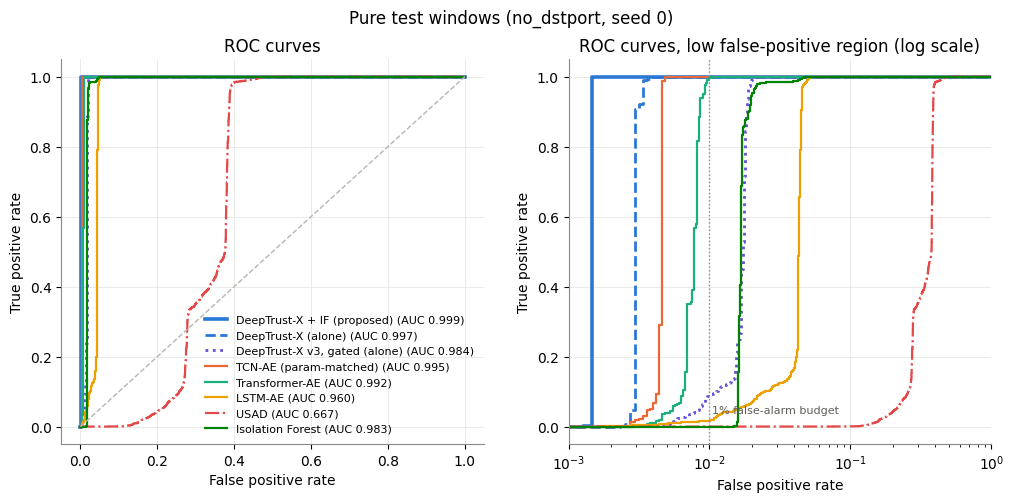

saved figA_roc_no_dstport


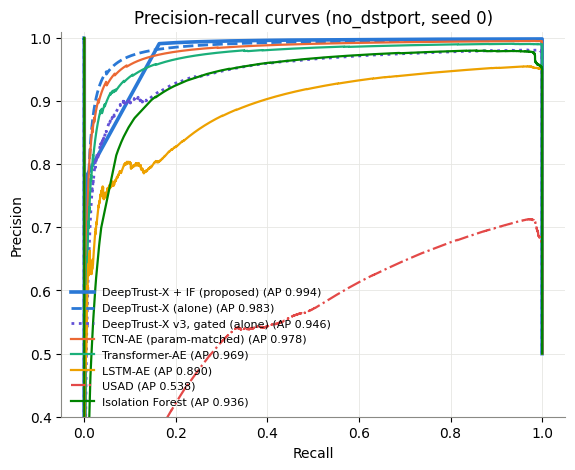

saved figB_pr_no_dstport


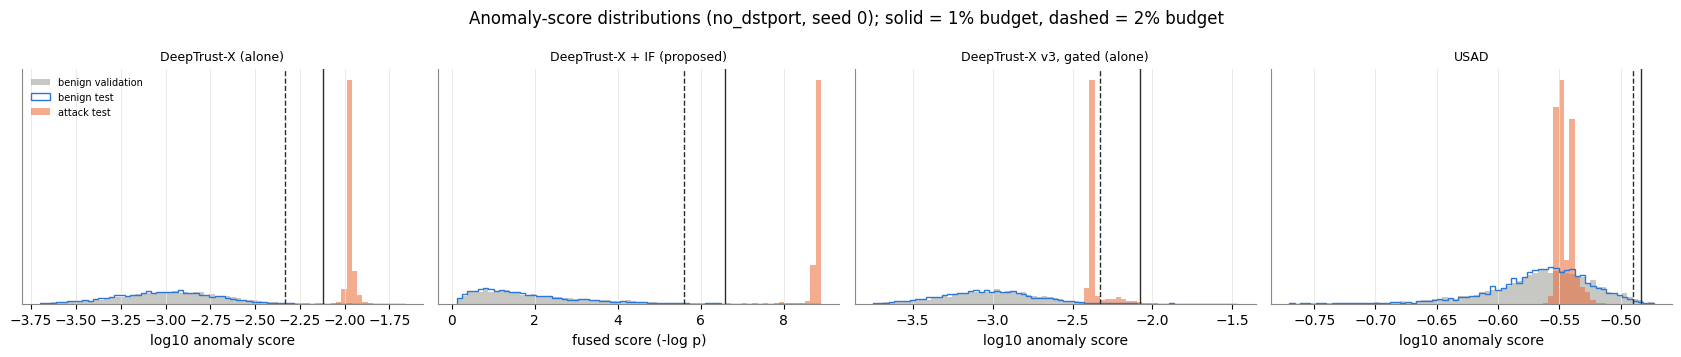

saved figC_score_distributions_no_dstport


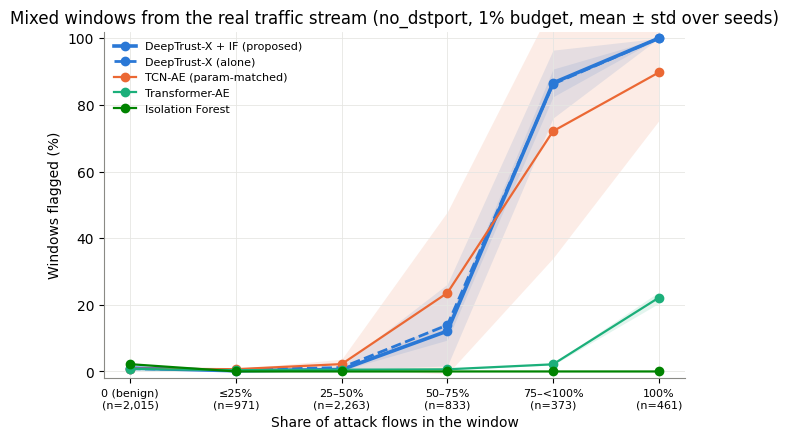

saved figD_mixed_by_fraction_no_dstport


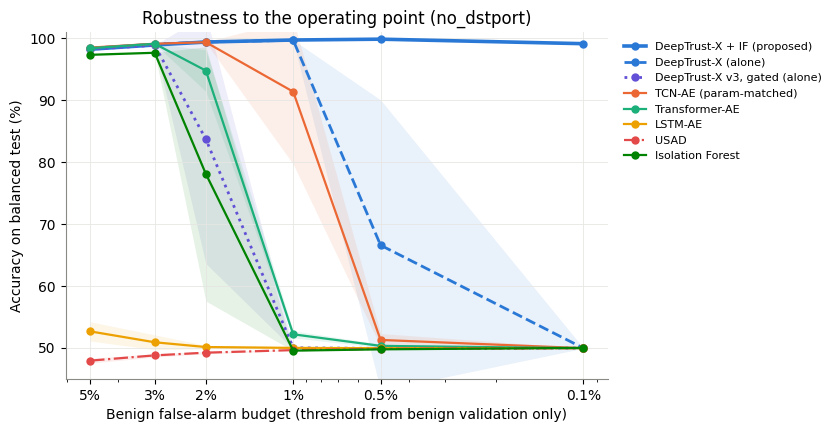

saved figE_budget_sweep_no_dstport


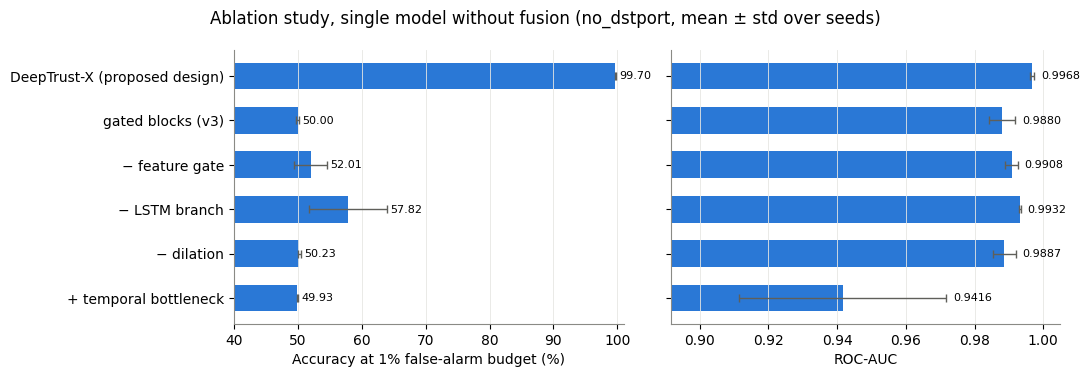

saved figF_ablation_no_dstport


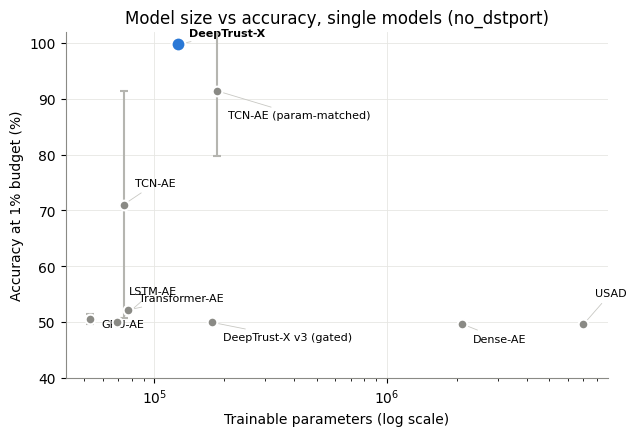

saved figG_size_vs_accuracy_no_dstport


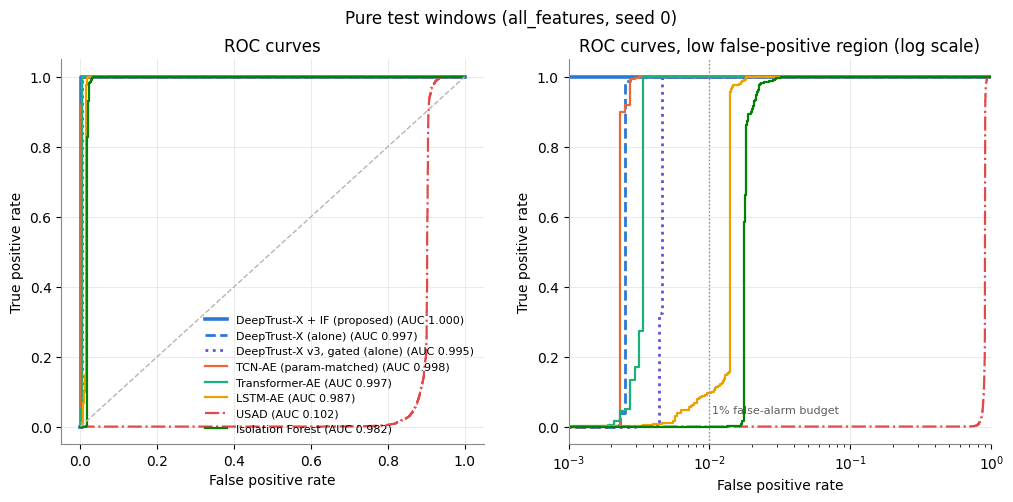

saved figA_roc_all_features


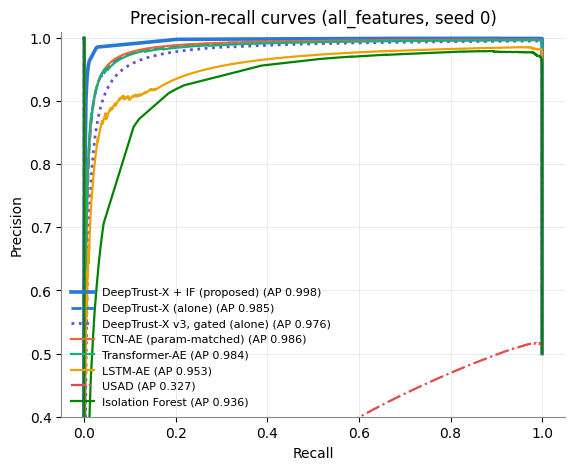

saved figB_pr_all_features


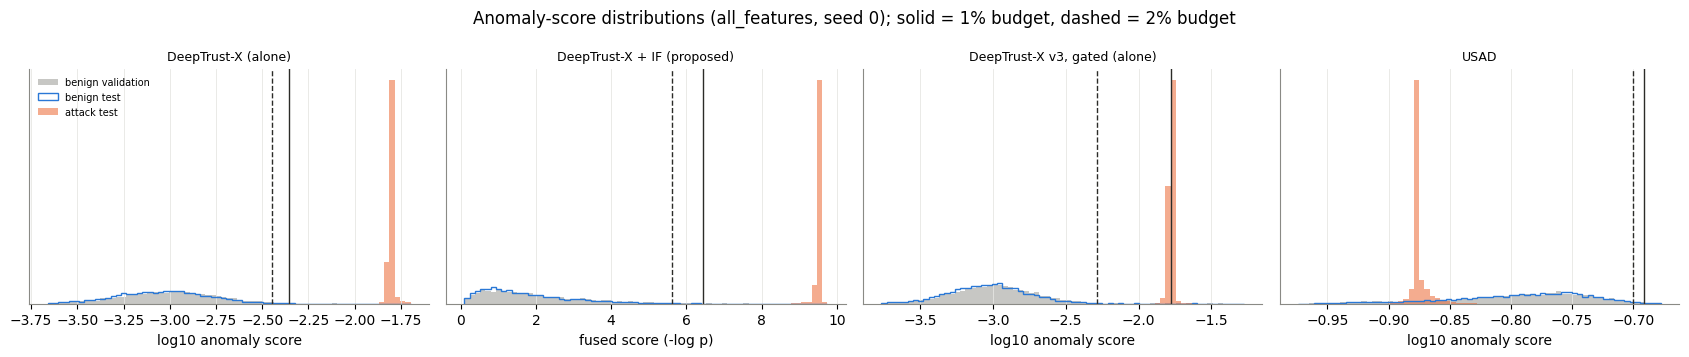

saved figC_score_distributions_all_features


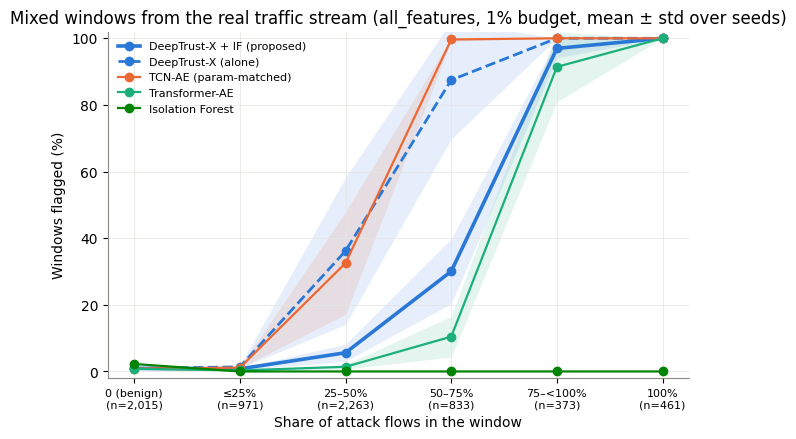

saved figD_mixed_by_fraction_all_features


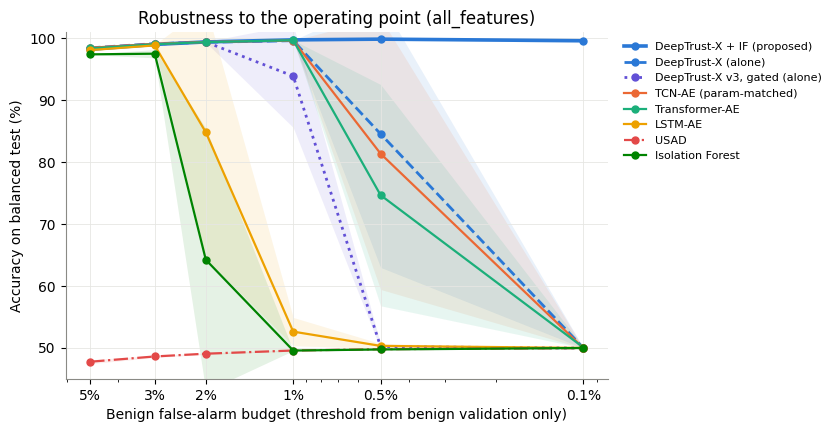

saved figE_budget_sweep_all_features


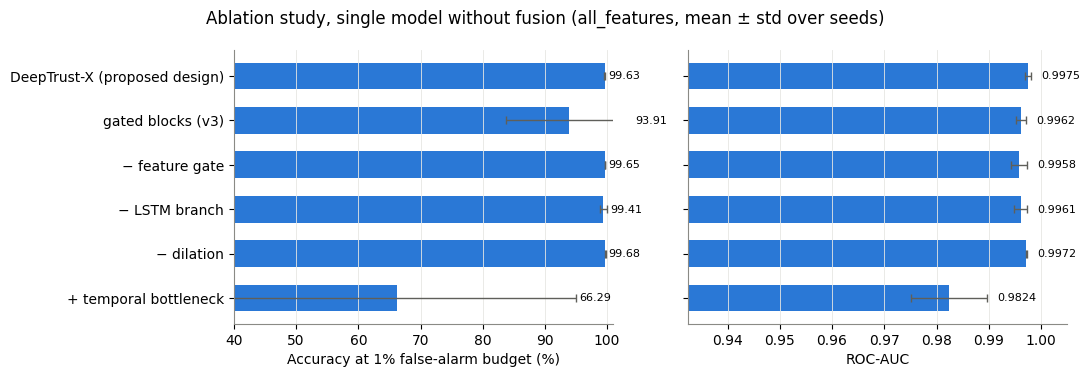

saved figF_ablation_all_features


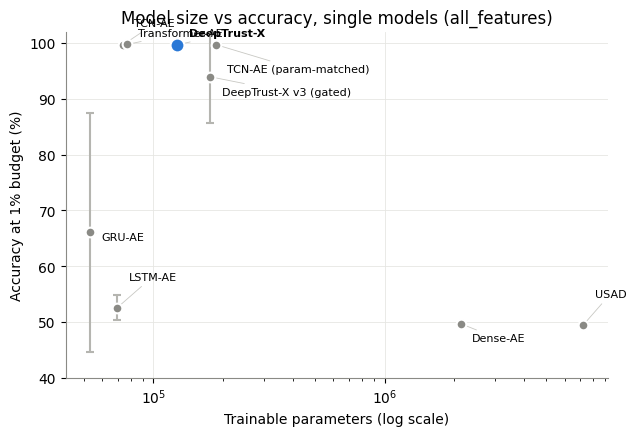

saved figG_size_vs_accuracy_all_features


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# PAPER FIGURES from the saved runs (CPU only, no training). Produces every remaining figure for the paper.
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
try:
    from google.colab import drive, files
    drive.mount("/content/drive"); SAVE = "/content/drive/MyDrive/deeptrust_runs_v4"; OUT = "/content/paper_figures"
except Exception:
    files = None; SAVE, OUT = "deeptrust_runs_v4", "paper_figures"
SAVE = globals().get("SAVE_OVERRIDE", SAVE); OUT = globals().get("OUT_OVERRIDE", OUT)
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8a85", "legend.frameon": False})
SETTINGS = ("no_dstport", "all_features"); SEEDS = (0, 1, 2); Q = 0.99
# validated categorical palette, fixed order; line style is a second cue so colour is never the only one
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
KEY = [  # (run name, variant, label, colour, line style, width)
    ("Ablation: ungated blocks", "fused", "DeepTrust-X + IF (proposed)", C[0], "-", 2.6),
    ("Ablation: ungated blocks", "alone", "DeepTrust-X (alone)", C[0], "--", 2.0),
    ("DeepTrust-X v3 (Proposed)", "alone", "DeepTrust-X v3, gated (alone)", C[6], ":", 2.0),
    ("TCN-AE (param-matched)", "alone", "TCN-AE (param-matched)", C[1], "-", 1.6),
    ("Transformer-AE", "alone", "Transformer-AE", C[2], "-", 1.6),
    ("LSTM-AE", "alone", "LSTM-AE", C[3], "-", 1.6),
    ("USAD", "alone", "USAD", C[7], "-.", 1.6),
    ("Isolation Forest", "alone", "Isolation Forest", C[5], "-", 1.6),
]
safe = lambda n: re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_")
def load(tag, name, seed):
    f = f"{SAVE}/{tag}__{safe(name)}__s{seed}.npz"; return np.load(f) if os.path.exists(f) else None
def tail(refv, s):
    r = np.sort(refv); n = len(r); ge = n - np.searchsorted(r, s, side="left"); return -np.log((ge + 1) / (n + 1))
def scores(tag, name, var, seed):
    d = load(tag, name, seed)
    if d is None: return None
    if var == "alone": return {k: d[k] for k in ("valB", "test", "mix")}
    I = load(tag, "Isolation Forest", seed)
    if I is None: return None
    N, NI = d["valB"][0::2], I["valB"][0::2]
    return {k: tail(N, d[k]) + tail(NI, I[k]) for k in ("valB", "test", "mix")}
def save(fig, name):
    for ext in ("png", "pdf"): fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show(); print("saved", name)

for tag in SETTINGS:
    lf = f"{SAVE}/{tag}__labels.npz"
    if not os.path.exists(lf): print("skipping", tag); continue
    lab = np.load(lf); y, ym, mf = lab["y_test"], lab["y_mix"], lab["mix_frac"]
    S0 = {k[2]: scores(tag, k[0], k[1], SEEDS[0]) for k in KEY}

    # ---- Fig A: ROC (full and low-FPR), pure test windows, seed 0 ----
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for name, var, lbl, col, ls, lw in KEY:
        s = S0[lbl]
        if s is None: continue
        fpr, tpr, _ = roc_curve(y, s["test"])
        ax[0].plot(fpr, tpr, color=col, ls=ls, lw=lw, label=f"{lbl} (AUC {roc_auc_score(y, s['test']):.3f})")
        ax[1].plot(np.clip(fpr, 1e-4, 1), tpr, color=col, ls=ls, lw=lw)
    ax[0].plot([0, 1], [0, 1], color="#b5b5b0", lw=1, ls="--")
    ax[1].set_xscale("log"); ax[1].set_xlim(1e-3, 1); ax[1].axvline(0.01, color="#8a8a85", lw=1, ls=":")
    ax[1].text(0.0105, 0.04, "1% false-alarm budget", fontsize=8, color="#5f5f5a")
    for a, t in zip(ax, ("ROC curves", "ROC curves, low false-positive region (log scale)")):
        a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate"); a.set_title(t)
    ax[0].legend(fontsize=8, loc="lower right"); fig.suptitle(f"Pure test windows ({tag}, seed {SEEDS[0]})")
    save(fig, f"figA_roc_{tag}")

    # ---- Fig B: precision-recall curves, seed 0 ----
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for name, var, lbl, col, ls, lw in KEY:
        s = S0[lbl]
        if s is None: continue
        p, r, _ = precision_recall_curve(y, s["test"])
        ax.plot(r, p, color=col, ls=ls, lw=lw, label=f"{lbl} (AP {average_precision_score(y, s['test']):.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0.4, 1.01)
    ax.set_title(f"Precision-recall curves ({tag}, seed {SEEDS[0]})"); ax.legend(fontsize=8, loc="lower left")
    save(fig, f"figB_pr_{tag}")

    # ---- Fig C: score distributions with the label-free thresholds (the reviewer's histogram request) ----
    show = ["DeepTrust-X (alone)", "DeepTrust-X + IF (proposed)", "DeepTrust-X v3, gated (alone)", "USAD"]
    fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 3.6))
    for ax, lbl in zip(axes, show):
        s = S0[lbl]
        if s is None: ax.set_visible(False); continue
        vb, tb, ta = s["valB"][1::2], s["test"][y == 0], s["test"][y == 1]
        pos = np.r_[vb, tb, ta] > 0
        log = "IF" not in lbl and pos.all()
        f = np.log10 if log else (lambda v: v)
        lo, hi = np.percentile(f(np.r_[vb, tb, ta]), [0.2, 99.8]); bins = np.linspace(lo, hi, 70)
        ax.hist(f(vb), bins, density=True, alpha=0.55, color="#9a9a94", label="benign validation")
        ax.hist(f(tb), bins, density=True, histtype="step", lw=1.8, color=C[0], label="benign test")
        ax.hist(f(ta), bins, density=True, alpha=0.55, color=C[1], label="attack test")
        for q, st in ((0.99, "-"), (0.98, "--")):
            ax.axvline(f(np.quantile(vb, q)), color="#2b2b28", lw=1, ls=st)
        ax.set_title(lbl, fontsize=9); ax.set_xlabel("log10 anomaly score" if log else "fused score (-log p)")
        ax.set_yticks([])
    axes[0].legend(fontsize=7, loc="upper left")
    fig.suptitle(f"Anomaly-score distributions ({tag}, seed {SEEDS[0]}); solid = 1% budget, dashed = 2% budget")
    plt.tight_layout(); save(fig, f"figC_score_distributions_{tag}")

    # ---- Fig D: mixed windows, detection rate vs share of attack flows in the window (mean ± std over seeds) ----
    edges = [0, 1e-9, 0.25, 0.5, 0.75, 0.9999, 1.0001]; names_ = ["0 (benign)", "≤25%", "25–50%", "50–75%", "75–<100%", "100%"]
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for name, var, lbl, col, ls, lw in [k for k in KEY if k[2] in ("DeepTrust-X + IF (proposed)", "DeepTrust-X (alone)",
                                                                  "TCN-AE (param-matched)", "Transformer-AE", "Isolation Forest")]:
        R = []
        for seed in SEEDS:
            s = scores(tag, name, var, seed)
            if s is None: continue
            p = s["mix"] > np.quantile(s["valB"][1::2], Q)
            R.append([100 * p[(mf >= edges[i]) & (mf < edges[i + 1])].mean() if ((mf >= edges[i]) & (mf < edges[i + 1])).any() else np.nan
                      for i in range(len(names_))])
        if not R: continue
        R = np.array(R); m, sd = np.nanmean(R, 0), np.nanstd(R, 0)
        ax.plot(range(len(names_)), m, color=col, ls=ls, lw=lw, marker="o", ms=6, label=lbl)
        ax.fill_between(range(len(names_)), m - sd, m + sd, color=col, alpha=0.12, lw=0)
    counts = [int(((mf >= edges[i]) & (mf < edges[i + 1])).sum()) for i in range(len(names_))]
    ax.set_xticks(range(len(names_))); ax.set_xticklabels([f"{n}\n(n={c:,})" for n, c in zip(names_, counts)], fontsize=8)
    ax.set_xlabel("Share of attack flows in the window"); ax.set_ylabel("Windows flagged (%)"); ax.set_ylim(-2, 102)
    ax.set_title(f"Mixed windows from the real traffic stream ({tag}, 1% budget, mean ± std over seeds)")
    ax.legend(fontsize=8, loc="upper left"); save(fig, f"figD_mixed_by_fraction_{tag}")

    # ---- Fig E: accuracy vs false-alarm budget (label-free thresholds), mean ± std over seeds ----
    qs = np.array([0.95, 0.97, 0.98, 0.99, 0.995, 0.999])
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, var, lbl, col, ls, lw in KEY:
        A = []
        for seed in SEEDS:
            s = scores(tag, name, var, seed)
            if s is None: continue
            A.append([100 * ((s["test"] > np.quantile(s["valB"][1::2], q)) == y).mean() for q in qs])
        if not A: continue
        A = np.array(A); xs = 100 * (1 - qs)
        ax.plot(xs, A.mean(0), color=col, ls=ls, lw=lw, marker="o", ms=5, label=lbl)
        ax.fill_between(xs, A.mean(0) - A.std(0), A.mean(0) + A.std(0), color=col, alpha=0.10, lw=0)
    ax.set_xscale("log"); ax.set_xticks(100 * (1 - qs)); ax.set_xticklabels([f"{v:g}%" for v in 100 * (1 - qs)])
    ax.invert_xaxis(); ax.set_xlabel("Benign false-alarm budget (threshold from benign validation only)")
    ax.set_ylabel("Accuracy on balanced test (%)"); ax.set_ylim(45, 101)
    ax.set_title(f"Robustness to the operating point ({tag})")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    save(fig, f"figE_budget_sweep_{tag}")

    # ---- Fig F: ablation (accuracy at 1% budget and ROC-AUC, mean ± std) ----
    ABL = [("Ablation: ungated blocks", "DeepTrust-X (proposed design)"), ("DeepTrust-X v3 (Proposed)", "gated blocks (v3)"),
           ("Ablation: no feature gate", "− feature gate"), ("Ablation: no LSTM branch", "− LSTM branch"),
           ("Ablation: no dilation (d=1)", "− dilation"), ("Ablation: + temporal compression", "+ temporal bottleneck")]
    rows = []
    for name, lbl in ABL:
        for seed in SEEDS:
            s = scores(tag, name, "alone", seed)
            if s is None: continue
            rows.append(dict(lbl=lbl, acc=100 * ((s["test"] > np.quantile(s["valB"][1::2], Q)) == y).mean(), auc=roc_auc_score(y, s["test"])))
    if rows:
        df = pd.DataFrame(rows).groupby("lbl", sort=False).agg(["mean", "std"])
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); yy = np.arange(len(df))
        for a, col_, t, xl in ((ax[0], "acc", "Accuracy at 1% false-alarm budget (%)", (40, 101)), (ax[1], "auc", "ROC-AUC", None)):
            a.barh(yy, df[col_]["mean"], xerr=df[col_]["std"].fillna(0), color=C[0], height=0.6, error_kw=dict(lw=1, capsize=3, ecolor="#5f5f5a"))
            a.set_yticks(yy); a.set_yticklabels(df.index if a is ax[0] else []); a.invert_yaxis(); a.set_xlabel(t); a.grid(axis="y", visible=False)
            for i, (m_, s_) in enumerate(zip(df[col_]["mean"], df[col_]["std"].fillna(0))):
                a.text(m_ + s_ + (0.5 if col_ == "acc" else 0.002), i, f"{m_:.2f}" if col_ == "acc" else f"{m_:.4f}", va="center", fontsize=8)
            if xl: a.set_xlim(*xl)
        ax[1].set_xlim(max(0, df["auc"]["mean"].min() - 0.05), 1.005)
        fig.suptitle(f"Ablation study, single model without fusion ({tag}, mean ± std over seeds)"); plt.tight_layout()
        save(fig, f"figF_ablation_{tag}")

    # ---- Fig G: model size vs accuracy (single models at the 1% budget) ----
    SIZE = [("Ablation: ungated blocks", "DeepTrust-X"), ("DeepTrust-X v3 (Proposed)", "DeepTrust-X v3 (gated)"), ("LSTM-AE", "LSTM-AE"),
            ("GRU-AE", "GRU-AE"), ("TCN-AE", "TCN-AE"), ("TCN-AE (param-matched)", "TCN-AE (param-matched)"),
            ("Transformer-AE", "Transformer-AE"), ("Dense-AE", "Dense-AE"), ("USAD", "USAD")]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (name, lbl) in enumerate(SIZE):
        acc, par = [], None
        for seed in SEEDS:
            d = load(tag, name, seed)
            if d is None: continue
            par = int(d["params"]) if "params" in d.files else par
            acc.append(100 * ((d["test"] > np.quantile(d["valB"][1::2], Q)) == y).mean())
        if not acc or par is None: continue
        hl = lbl == "DeepTrust-X"
        ax.errorbar(par, np.mean(acc), yerr=np.std(acc), fmt="o", ms=10 if hl else 7, color=C[0] if hl else "#8a8a85",
                    mec="white", mew=1.5, ecolor="#b5b5b0", capsize=3, zorder=3)
        ax.annotate(lbl, (par, np.mean(acc)), xytext=(8, (-1) ** i * (6 + 7 * (i % 3))), textcoords="offset points", fontsize=8,
                    fontweight="bold" if hl else "normal", arrowprops=dict(arrowstyle="-", color="#c8c8c3", lw=0.6))
    ax.set_xscale("log"); ax.set_xlabel("Trainable parameters (log scale)"); ax.set_ylabel("Accuracy at 1% budget (%)")
    ax.set_ylim(40, 102); ax.set_title(f"Model size vs accuracy, single models ({tag})"); save(fig, f"figG_size_vs_accuracy_{tag}")

if files:
    import shutil; files.download(shutil.make_archive(OUT, "zip", OUT))